# E122 · Why do three buses arrive together? Four models, one holding rule, and the path between them

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: every recorded pass of a bus at a timepoint of **MBTA route 111** (Woodlawn - Haymarket, Boston), September to November 2024, from the agency's open "Bus Arrival Departure Times" file, and the season's average boardings per stop from its passenger counters (both marked CC0) |
| **You will learn** | Chaining models so that each one feeds the next: **travel times** with traffic that successive buses share · **dwell** inferred through the gap to the bus ahead, because the records do not contain it · a **simulator of coupled headways**, replayed on days it has not seen · a **holding rule** judged in rider time · two pictures for things that move, the **time-space (Marey) diagram** with posterior ribbons and the **headway phase portrait** · and, at every step, what we chose, what we rejected and what would change our mind |

## The question

You wait twelve minutes for a bus that should come every six, and then two arrive together, sometimes
three. Everybody who has used a busy route knows this, and most people suspect the drivers. The
usual explanation needs no culprit. A bus that falls a little behind finds more passengers waiting
at each stop, because they have had longer to gather. Boarding them takes time, so it falls further
behind. The bus after it finds fewer passengers than usual and catches up. The gap in front of the
late bus grows, the gap behind it shrinks, and the two end up travelling as a pair. The even spacing
of the timetable is an unstable equilibrium, like a pencil balanced on its point. The analysis usually
cited as the first is Newell and Potts (1964), and the remedies studied since work by holding buses
back: Daganzo (2009) sets the holding time at control points from the gaps measured in real time,
and Bartholdi and Eisenstein (2012) drop the timetable altogether and let the gaps equalise
themselves, a scheme they ran on a bus route in Atlanta.

This notebook asks the question for one real route. The MBTA's route 111 carries people from Chelsea
over the Tobin Bridge to Haymarket in central Boston, every four to six minutes all day, and the
agency publishes when each bus passed each of ten timepoints. An operations planner wants to know
two things: where the bunches come from, and whether holding buses, somewhere, for some time, would
give riders back more minutes than it takes from them.

No single model answers that. We need to know how long a bus takes between timepoints, how that
time depends on the gap to the bus ahead, what happens when a whole day of buses follow one another
under those rules, and what a holding rule would change. Each is a model with defensible rivals, and
the first version we try is usually wrong. The proposal we started from was simple: model the
segments independently and bunching can never appear; put the passenger loop in and it does. We test
that proposal instead of assuming it. Part of it survives, and the source of bunching that costs
riders most on this route turns out to be something the proposal does not mention.

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from numba import njit

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub; nothing here uses JAX (see E89, E118)

RANDOM_SEED = 122
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.titlesize": 11})
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
T_START = time.time()

INK, MUTED, LIGHT, GRID = "#222222", "#8a8a8a", "#d9d9d9", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SEQ = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def tidy(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.6)
    ax.set_axisbelow(True)

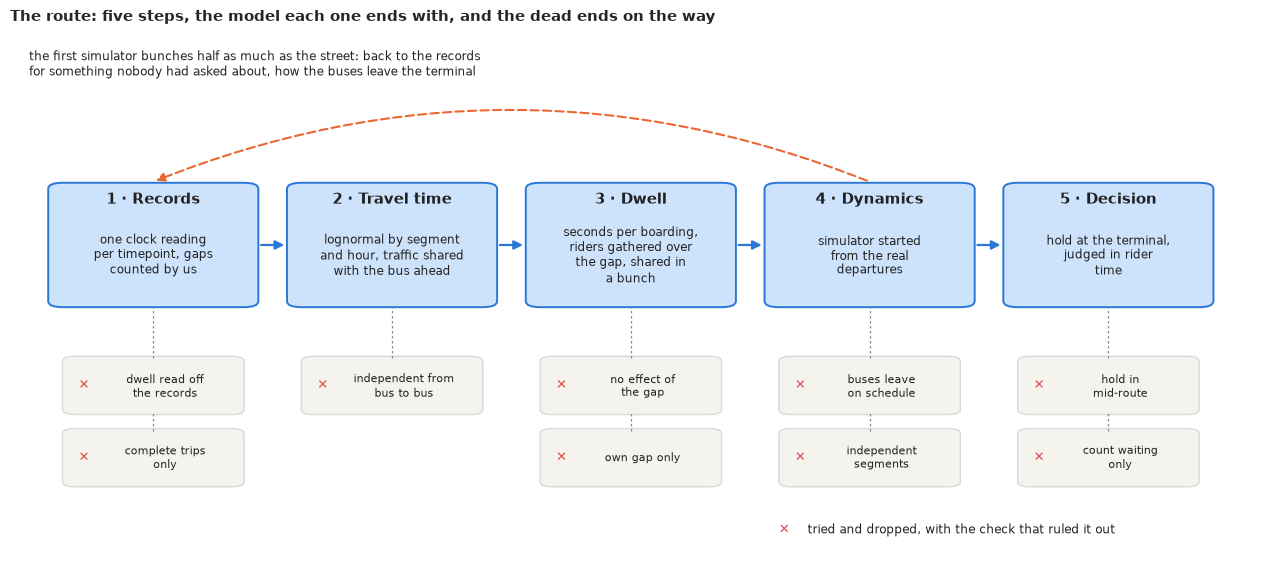

In [2]:
ROUTE = [  # step, what we end up using, what we try and drop on the way
    ("1 · Records", "one clock reading\nper timepoint, gaps\ncounted by us", ["dwell read off\nthe records", "complete trips\nonly"]),
    ("2 · Travel time", "lognormal by segment\nand hour, traffic shared\nwith the bus ahead", ["independent from\nbus to bus"]),
    ("3 · Dwell", "seconds per boarding,\nriders gathered over\nthe gap, shared in\na bunch", ["no effect of\nthe gap", "own gap only"]),
    ("4 · Dynamics", "simulator started\nfrom the real\ndepartures", ["buses leave\non schedule", "independent\nsegments"]),
    ("5 · Decision", "hold at the terminal,\njudged in rider\ntime", ["hold in\nmid-route", "count waiting\nonly"]),
]

fig, ax = plt.subplots(figsize=(12.5, 5.6))
for i, (step, kept, dropped) in enumerate(ROUTE):
    ax.add_patch(FancyBboxPatch((i - 0.42, 2.45), 0.84, 1.2, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc="#cde2fb", ec=BLUE, lw=1.4))
    ax.text(i, 3.5, step, ha="center", va="center", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(i, 2.95, kept, ha="center", va="center", fontsize=8.6, color=INK, linespacing=1.25)
    if i < len(ROUTE) - 1:
        ax.add_patch(FancyArrowPatch((i + 0.44, 3.05), (i + 0.56, 3.05), arrowstyle="-|>", mutation_scale=13,
                                     color=BLUE, lw=1.6))
    for k, text in enumerate(dropped):
        y = 1.65 - 0.72 * k
        ax.plot([i, i], [y + 0.27, y + 0.45 if k else 2.43], color=MUTED, lw=0.9, ls=(0, (2, 2)))
        ax.add_patch(FancyBboxPatch((i - 0.36, y - 0.27), 0.72, 0.54, boxstyle="round,pad=0.02,rounding_size=0.05",
                                    fc="#f4f3ee", ec=LIGHT, lw=1.0))
        ax.text(i - 0.29, y, "✕", ha="center", va="center", fontsize=9, color=RED, fontweight="bold")
        ax.text(i + 0.05, y, text, ha="center", va="center", fontsize=8.2, color=INK, linespacing=1.2)
ax.add_patch(FancyArrowPatch((3.0, 3.68), (0, 3.68), connectionstyle="arc3,rad=0.2", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.text(-0.52, 4.85, "the first simulator bunches half as much as the street: back to the records\n"
        "for something nobody had asked about, how the buses leave the terminal", ha="left", va="center",
        fontsize=8.6, color=INK)
ax.text(2.62, 0.21, "✕", fontsize=9, color=RED, fontweight="bold", va="center")
ax.text(2.74, 0.21, "tried and dropped, with the check that ruled it out", fontsize=8.6, color=INK, va="center")
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(-0.1, 5.2)
ax.axis("off")
ax.set_title("The route: five steps, the model each one ends with, and the dead ends on the way", loc="left");

Blue boxes are the steps and the model each one ends with. Grey boxes are what we try first and drop,
each ruled out by a check we show. The orange arrow is the moment the analysis runs backwards.

Each step closes with a short box, **The choice**, that records what we kept, what we rejected and
why, and what evidence would make us choose differently. The last part redoes the decision under the
rejected choices, to see which of them would have changed the rule and which only changed how much
we expected from it.

| part | question | tool |
|---|---|---|
| 1 | What does a bus leave behind in the records, and what is a gap? | a time-space diagram, gaps counted along the route |
| 2 | How long does a bus take from one timepoint to the next? | lognormal regressions, noise tied to the bus ahead |
| 3 | Does a longer gap make a slower bus? | a natural experiment, a dwell term driven by boardings |
| 4 | Do the pieces, put together, bunch like the real route? | a simulator replayed on an unseen month, a phase portrait, posterior ribbons |
| 5 | Where should buses be held, and for how long? | rider time with and without the rule, on the same days |
| 6 | Which of our choices mattered? | the decision redone under every rejected choice |

## 1 · The records: what a bus leaves behind

In [3]:
data.describe("e122_bus_events")
events = data.load("e122_bus_events")
print()
data.describe("e122_bus_ridership")
riders = data.load("e122_bus_ridership")
print(f"\n{len(events):,} readings of {events.groupby(['date', 'direction', 'trip']).ngroups:,} one-way trips on "
      f"{events['date'].nunique()} days; without a clock reading: {events['actual_s'].isna().mean():.1%}")
events.head(4)

e122_bus_events: Bus route 111 (Woodlawn - Haymarket), 1 September to 30 November 2024, one row per bus and TIMEPOINT (326,250 rows, 32,625 one-way trips, ten timepoints each): date (service date), direction (Inbound = towards Haymarket), trip (the agency's half_trip_id), seq (order of the timepoint, 1-10), timepoint (its code: woodc, garfi, smore, wacry, belsq, thche, tobin, ruthf, cacom, hayms inbound), stop_id, standard (Headway or Schedule), sched_s and actual_s (scheduled and actual DEPARTURE from the timepoint, arrival at the last one, in seconds after local midnight, above 86,400 after midnight; actual_s is empty for 3.9% of rows), sched_headway and headway (the agency's scheduled and actual gap to the previous trip at that timepoint, s). One clock reading per timepoint: the time spent standing at stops is not recorded separately, and there are no passenger counts per bus.
  source: 'MBTA Bus Arrival Departure Times 2024', open-data portal of the Massachusetts Bay Transportation

,date,direction,trip,seq,timepoint,stop_id,standard,sched_s,actual_s,sched_headway,headway
0,2024-09-01,Inbound,64241748,1,woodc,5547,Headway,78180,78298.0,900.0,900.0
1,2024-09-01,Inbound,64241748,2,garfi,5592,Headway,78300,78492.0,900.0,910.0
2,2024-09-01,Inbound,64241748,3,smore,5595,Headway,78360,78577.0,900.0,927.0
3,2024-09-01,Inbound,64241748,4,wacry,5602,Headway,78540,78804.0,900.0,909.0


Each row is one bus passing one **timepoint**. Route 111 has about twenty-five stops in each direction
and ten of them (or checkpoints near them) are timepoints. The file is called "Arrival Departure
Times", and we had hoped to read dwell straight off it: arrival at a stop, departure from it, and the
difference is the time spent standing. The data dictionary says otherwise. There is one clock reading
per row, `actual`, "the time the trip actually departed the timepoint", and at the last timepoint it
is the arrival. That is the first dead end, before any model: **dwell is not in the records**. Between
two timepoints we see only the total time, driving and standing together. Nor does the file say how
many people were on a bus. The second table gives the average boardings, alightings and load per
scheduled trip and stop over the autumn, from the automatic passenger counters: a season's averages,
not that day's riders. Part 3 will have to infer dwell from what the two tables can say together.

Three decisions come before any model.

**Which trips, on which days?** The inbound direction, from Woodlawn in Chelsea to Haymarket, on
Mondays to Fridays that ran the full weekday timetable of 216 trips (a few days list two to eleven
fewer). Labor Day, Indigenous Peoples' Day and Thanksgiving ran weekend timetables and fall out by
that rule; Veterans Day and the Friday after Thanksgiving ran the weekday timetable and we set them
aside by hand. That leaves 60 days. We model the hours from 5:00 to 20:00 and judge everything on
buses between 6:00 and 19:00.

**What is a gap?** The time between two successive buses at a timepoint, in the order in which
they actually passed it. Buses overtake each other, so this is not the order of the timetable.

**What about the missing readings?** About one scheduled trip in sixty has no reading at all, and we
take it as not run, which we cannot check. Another 7% miss some of their ten readings. The obvious
first attempt is to keep complete trips only, and it fails quietly: a bus that was really there
vanishes, and the gap around it doubles. So a bus with a missing reading is placed where its other
readings and the typical run of that hour put it, and its neighbours keep honest gaps. A filled-in
time is never used as data, not as a run time and not as one end of a gap, and when we test a
simulator we blind it at exactly the places where the record is blind.

In [4]:
TP = ["woodc", "garfi", "smore", "wacry", "belsq", "thche", "tobin", "ruthf", "cacom", "hayms"]
NAME = ["Woodlawn", "Garfield Ave", "Sagamore Ave", "Cary Ave", "Bellingham Sq", "Third St",
        "Tobin Bridge", "Rutherford Ave", "Causeway St", "Haymarket"]
H0, NH = 5, 15                                     # hours of the day we model: 5:00 to 20:00
W0, W1 = 6 * 3600, 19 * 3600                       # hours we judge: 6:00 to 19:00

inbound = events[events["direction"] == "Inbound"].assign(date=lambda d: pd.to_datetime(d["date"]))
actual = inbound.pivot(index=["date", "trip"], columns="seq", values="actual_s").astype(float)
sched_start = inbound[inbound["seq"] == 1].set_index(["date", "trip"])["sched_s"].astype(float)
per_day = actual.groupby(level=0).size()
SPECIAL = pd.to_datetime(["2024-11-11", "2024-11-29"])        # Veterans Day, the Friday after Thanksgiving
ordinary = per_day.index[(per_day.index.dayofweek < 5) & (per_day > 200) & ~per_day.index.isin(SPECIAL)]
actual = actual[actual.index.get_level_values(0).isin(ordinary)]
print("timepoints, inbound:", ", ".join(f"{code} = {name}" for code, name in zip(TP, NAME)))
print(f"inbound trips per day: {per_day.value_counts().sort_index(ascending=False).head(4).to_dict()} ...")
print(f"ordinary weekdays: {len(ordinary)} with {len(actual):,} scheduled trips; no reading at all: "
      f"{actual.isna().all(axis=1).mean():.1%}; some but not all ten: "
      f"{(actual.isna().any(axis=1) & actual.notna().any(axis=1)).mean():.1%}")
actual = actual[actual.notna().any(axis=1)]
at_bell = inbound[inbound["seq"] == 5].sort_values(["date", "actual_s"])
ours = at_bell.groupby("date")["actual_s"].diff()
both = ours.notna() & at_bell["headway"].notna()
print(f"the agency's headway column equals our gap at Bellingham Sq for "
      f"{(ours[both] == at_bell.loc[both, 'headway']).mean():.0%} of the readings that have both")

complete = actual.dropna()
start_hour = (complete[1] // 3600).clip(H0, H0 + NH - 1).astype(int)
PROFILE = (complete.sub(complete[1], axis=0).groupby(start_hour).median()
           .reindex(range(H0, H0 + NH)).to_numpy())            # typical seconds from Woodlawn, by hour
Y_MIN = PROFILE[3:14].mean(0) / 60                               # where the timepoints sit on our diagrams


def fill(a):
    """Place a bus at the timepoints where its reading is missing, from its other readings and the
    typical run of that hour. Returns the completed times and a mask of what was really recorded."""
    seen = ~np.isnan(a)
    out = a.copy()
    for i in np.where(~seen.all(1))[0]:
        k = np.where(seen[i])[0]
        hour = int(np.clip((a[i, k[0]] - PROFILE[5, k[0]]) // 3600, H0, H0 + NH - 1))
        prof = PROFILE[hour - H0]
        out[i] = np.where(seen[i], a[i], prof + np.interp(np.arange(10), k, a[i, k] - prof[k]))
    return out, seen


DAYS = {}
for d, g in actual.groupby(level=0):
    dep, seen = fill(g.to_numpy())
    DAYS[d] = (dep, seen, sched_start.reindex(g.index).to_numpy())
TRAIN = [d for d in DAYS if d < pd.Timestamp("2024-11-01")]
TEST = [d for d in DAYS if d >= pd.Timestamp("2024-11-01")]


def gaps_at(dep, seen, k):
    """Gaps between successive recorded buses at timepoint k, for buses passing between 6:00 and 19:00."""
    t = np.sort(dep[seen[:, k], k])
    keep = (t[1:] >= W0) & (t[1:] < W1)
    return np.diff(t)[keep]


def route_stats(days):
    """Per timepoint: spread of the gaps, share under one minute, share over twelve, mean wait (minutes)."""
    out = np.empty((10, 4))
    for k in range(10):
        h = np.concatenate([gaps_at(dep, seen, k) for dep, seen in days])
        out[k] = h.std() / h.mean(), (h < 60).mean(), (h > 720).mean(), (h**2).mean() / (2 * h.mean()) / 60
    return out


STAT_NAMES = ["sd / mean of the gap", "gaps under 1 min", "gaps over 12 min", "mean wait (min)"]
real_all = route_stats([DAYS[d][:2] for d in DAYS])
only_complete = route_stats([(DAYS[d][0][DAYS[d][1].all(1)], DAYS[d][1][DAYS[d][1].all(1)]) for d in DAYS])
print(f"training days (September, October): {len(TRAIN)}; test days (November): {len(TEST)}")
print(f"gaps over 12 minutes at Third St: {real_all[5, 2]:.1%}; if trips with a missing reading are thrown "
      f"away: {only_complete[5, 2]:.1%}")
print("\nall 60 days, 6:00 to 19:00:")
print(pd.DataFrame(real_all, index=NAME, columns=STAT_NAMES).round(3).T.to_string())

timepoints, inbound: woodc = Woodlawn, garfi = Garfield Ave, smore = Sagamore Ave, wacry = Cary Ave, belsq = Bellingham Sq, thche = Third St, tobin = Tobin Bridge, ruthf = Rutherford Ave, cacom = Causeway St, hayms = Haymarket
inbound trips per day: {216: 51, 214: 2, 212: 3, 211: 2} ...
ordinary weekdays: 60 with 12,897 scheduled trips; no reading at all: 1.6%; some but not all ten: 6.9%
the agency's headway column equals our gap at Bellingham Sq for 100% of the readings that have both
training days (September, October): 42; test days (November): 18
gaps over 12 minutes at Third St: 12.1%; if trips with a missing reading are thrown away: 12.8%

all 60 days, 6:00 to 19:00:
                      Woodlawn  Garfield Ave  Sagamore Ave  Cary Ave  Bellingham Sq  Third St  Tobin Bridge  Rutherford Ave  Causeway St  Haymarket
sd / mean of the gap     0.684         0.709         0.766     0.835          0.885     0.923         0.914           0.921        0.939      0.925
gaps under 1 min       

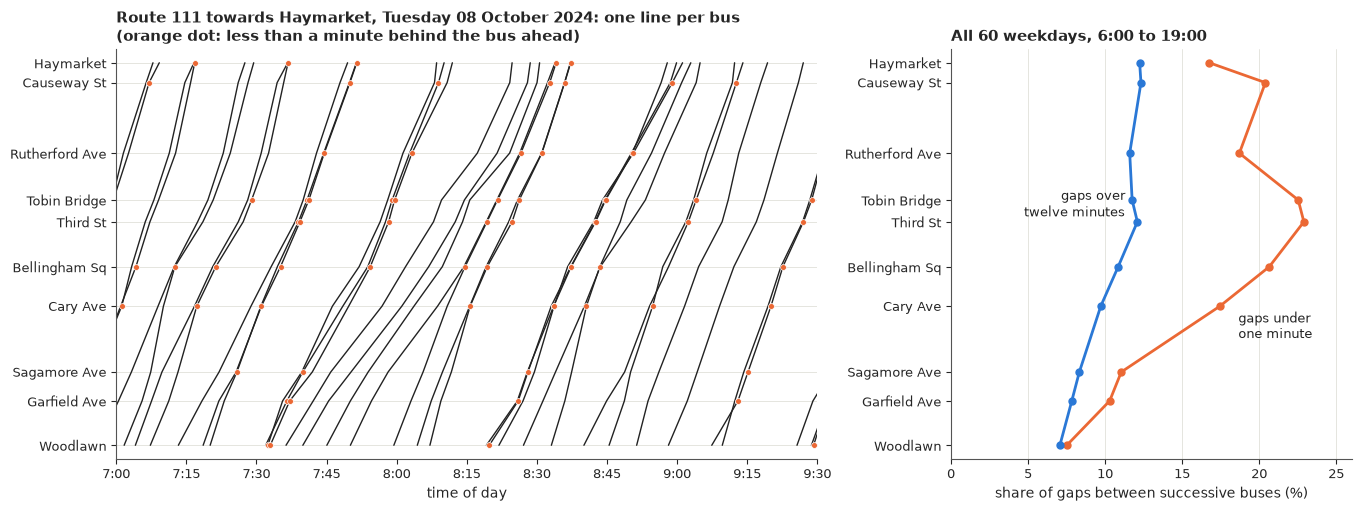

In [5]:
def marey(ax, dep, seen, t0, t1, colour=INK, lw=1.0, dots=True, alpha=1.0):
    """Time-space diagram: one line per bus, time across, the route up the page."""
    on = (dep[:, 0] > t0 - 2700) & (dep[:, 0] < t1)
    for row, ok in zip(dep[on], seen[on]):
        ax.plot(row / 3600, Y_MIN, color=colour, lw=lw, alpha=alpha, solid_capstyle="round")
    if dots:
        for k in range(10):
            t = np.sort(dep[on, k])
            close = t[1:][np.diff(t) < 60]
            ax.plot(close / 3600, np.full(len(close), Y_MIN[k]), "o", ms=4.2, color=ORANGE, mec="white", mew=0.5)
    ax.set_xlim(t0 / 3600, t1 / 3600)
    ax.set_yticks(Y_MIN, NAME)
    ticks = np.arange(np.ceil(t0 / 900), np.floor(t1 / 900) + 1) * 900
    ax.set_xticks(ticks / 3600, [f"{int(s // 3600)}:{int(s % 3600 // 60):02d}" for s in ticks])
    ax.set_ylim(-1, Y_MIN[-1] + 1)
    tidy(ax, grid="y")


SHOW_DAY = pd.Timestamp("2024-10-08")
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0), gridspec_kw={"width_ratios": [1.75, 1]})
marey(axes[0], *DAYS[SHOW_DAY][:2], 7 * 3600, 9.5 * 3600)
axes[0].set_title(f"Route 111 towards Haymarket, {SHOW_DAY:%A %d %B %Y}: one line per bus\n"
                  "(orange dot: less than a minute behind the bus ahead)", loc="left", fontsize=11)
axes[0].set_xlabel("time of day")
ax = axes[1]
ax.plot(real_all[:, 1] * 100, Y_MIN, "o-", color=ORANGE, lw=2, ms=5)
ax.plot(real_all[:, 2] * 100, Y_MIN, "o-", color=BLUE, lw=2, ms=5)
ax.text(real_all[3, 1] * 100 + 1.2, Y_MIN[3] - 0.3, "gaps under\none minute", color=INK, fontsize=9, va="top")
ax.text(real_all[5, 2] * 100 - 0.8, Y_MIN[5] + 0.4, "gaps over\ntwelve minutes", color=INK, fontsize=9, ha="right")
ax.set_yticks(Y_MIN, NAME)
ax.set_ylim(-1, Y_MIN[-1] + 1)
ax.set_xlim(0, 26)
ax.set_xlabel("share of gaps between successive buses (%)")
ax.set_title("All 60 weekdays, 6:00 to 19:00", loc="left")
tidy(ax, grid="x");

Dropping the incomplete trips would have raised the share of gaps over twelve minutes at Third St
from 12.1% to 12.8%: a small effect, all of it invented. The agency's own headway column equals our
gap wherever a reading has both. We count our own because the column is empty at the last timepoint
and because we also need, for every bus, the gap of the bus ahead and the gap to the bus behind.

The split is by calendar. September and October, 42 days, are for fitting. November, 18 days, is kept
for testing what the fitted models do when put together.

The picture on the left is a time-space diagram, also called a Marey diagram after Étienne-Jules
Marey, whose *La méthode graphique* made a train timetable drawn this way famous (he credited the
idea to the railway engineer Ibry). Time runs across and the route runs up the page, with the
timepoints spaced by the typical running time between them. A bus is a line, a steep line is a fast
bus, and an orange dot marks every bus that passed a timepoint less than a minute behind the one in
front. (The codes `tobin` and `ruthf` are not in the agency's current list of checkpoints. We read
them as the Tobin Bridge and Rutherford Avenue, which lie on the way.)

This one morning already contains the whole story, in two versions. Just after 8:19 three buses
leave Woodlawn within three minutes of each other, twelve minutes after the bus before them. They
pass Third St within half a minute of one another, more than seventeen minutes behind the bus ahead:
three buses arriving together, as promised. That bunch was made at the terminal. The other version
is the bus that leaves Woodlawn at 7:59, nine minutes after the one before it, and has caught it by
Third St. That bunch was made on the way.

The right panel and the table count this over all 60 days. Leaving Woodlawn, 7.5% of buses are less
than a minute behind another. By Third St it is 23%, three times as many, and one gap in eight is
longer than twelve minutes on a route timetabled every four to six. For a rider who turns up at
random, the mean wait is the mean of the squared gap over twice the mean gap, because long gaps are
both longer and more likely to be the one you arrive in. With perfectly even gaps it would be about
2.9 minutes here. It is 4.3 minutes at Woodlawn and 5.4 at Third St. And then the growth stops: from
Third St to Haymarket the spread of the gaps stays where it is. That stretch is the Tobin Bridge and
the highway into Boston, where the bus does not stop.

> **The choice.** One clock reading per bus and timepoint, inbound, on 60 ordinary weekdays; gaps
> counted by us in the order buses really passed; a bus with a missing reading is placed, never
> measured. *Rejected:* reading dwell off the records (it is not there), and keeping complete trips
> only (it removes real buses and invents long gaps). *What would change our mind:* the counters'
> raw records, one row per bus and stop with door times and riders. With those, dwell would be data
> and part 3 would be a regression.

## 2 · Travel time: how long from one timepoint to the next?

The unit of the analysis is a bus on a **segment**, the stretch from one timepoint to the next, and
its **run time** is the difference between its two clock readings. There are nine segments. The first
five are streets in Chelsea with stops where riders board. Then come three with next to none, over
the bridge and down the highway, and a short last stretch into Haymarket.

The first model is the one the proposal starts from. Every segment has a typical run time for each
hour of the day, and each bus draws its own luck around it:

$$\log T_{ik} = \underbrace{\ell_k + \eta_{k,\,\text{hour}}}_{\log B_{k,\text{hour}}} + z_{ik},
\qquad z_{ik} \sim \mathcal{N}(0, \sigma_k),$$

with a level $\ell_k$ per segment, a profile $\eta$ over the fifteen hours that sums to zero, and
noise $z$ that is **independent from bus to bus**.

The second model changes one thing. The bus ahead has just driven this segment, and if it was slow,
because of a double-parked van or a jam on the bridge, we probably will be too. So the noise of bus
$i$ leans on the noise of its leader, less so the longer ago the leader passed:

$$z_{ik} \mid z_{\text{lead},k} \sim \mathcal{N}\!\big(\rho_k(h)\,z_{\text{lead},k},\ \sigma_k\sqrt{1-\rho_k(h)^2}\big),
\qquad \rho_k(h) = \rho_{0k}\,e^{-h/\lambda_k},$$

where $h$ is the gap between the two buses when they set off. This is what a slowly changing state of
the street looks like when it is read at the moments buses pass (an Ornstein-Uhlenbeck process),
and it keeps the spread of a single bus at $\sigma_k$ whatever the tie. We call it **traffic**. Both
models are fitted to the rows built from real readings.

In [6]:
def pair_table(days):
    """One row per bus and segment: its run time, the gap to the bus ahead when it set off, that
    leader's own gap, and the gap to the bus behind. `ok` marks rows built from real readings only."""
    rows = []
    for d, (dep, seen, _) in days.items():
        for k in range(9):
            o = np.argsort(dep[:, k])
            t, s0 = dep[o, k], seen[o, k]
            h = np.r_[np.nan, np.diff(t)]
            real_gap = s0 & np.r_[False, s0[:-1]]
            rows.append(pd.DataFrame({
                "date": d, "k": k, "t": t, "run": dep[o, k + 1] - t, "h": h, "h_lead": np.r_[np.nan, h[:-1]],
                "h_behind": np.r_[h[1:], np.nan],
                "ok": seen[o, k + 1] & real_gap & np.r_[False, real_gap[:-1]] & np.r_[real_gap[1:], False]}))
    p = pd.concat(rows, ignore_index=True)
    p["ok"] &= (p["t"] >= H0 * 3600) & (p["t"] < (H0 + NH) * 3600) & (p["run"] >= 20) & (p["h"] < 2400)
    same_block = (p["k"] == p["k"].shift(1)) & (p["date"] == p["date"].shift(1))
    p["lead"] = np.where(p["ok"] & p["ok"].shift(1, fill_value=False) & same_block, p.index - 1, -1)
    p["hi"] = (p["t"] // 3600).astype(int) - H0
    return p[p["ok"]].drop(columns="ok")


pairs = pair_table(DAYS)
train_rows = pairs[pairs["date"].isin(TRAIN)]
print(f"bus-segment rows from real readings: {len(pairs):,}; on the {len(TRAIN)} training days: {len(train_rows):,}")

SEG = [f"{NAME[i]} - {NAME[i + 1]}" for i in range(9)]
seg_of_stop = np.searchsorted([0, 6, 9, 15, 18, 20, 21, 22, 23], riders["stop_seq"], side="left") - 1
rin = riders.assign(seg=seg_of_stop, hour=riders["trip_start"] // 3600)[riders["direction"] == "Inbound"]
hours = range(H0, H0 + NH)
RATE = (rin[rin["seg"] >= 0].groupby(["seg", "hour"])["boardings"].sum().unstack(fill_value=0.0)
        .reindex(index=range(9), columns=hours, fill_value=0.0).to_numpy() / 3600.0)     # boardings per second
RATE0 = rin[rin["seg"] < 0].groupby("hour")["boardings"].sum().reindex(hours, fill_value=0.0).to_numpy() / 3600.0
N_POST = 200


def fit_segments(rows, segments, traffic, gap):
    """Run time of a bus on a segment. traffic: its noise is tied to the bus ahead, less so the further
    ahead that bus is. gap: 'none', 'own' (riders gathered since the bus ahead) or 'shared' (a bunch
    splits them)."""
    rows = rows[rows["k"].isin(segments)]
    pos = pd.Series(np.arange(len(rows)), index=rows.index)
    k, hi = pd.Index(segments).get_indexer(rows["k"]), rows["hi"].to_numpy()
    h, hl, hb = (np.minimum(rows[c].to_numpy(), 2400.0) for c in ("h", "h_lead", "h_behind"))
    lead = rows["lead"].map(pos).fillna(-1).astype(int).to_numpy()
    log_run = np.log(rows["run"].to_numpy())
    rate = RATE[rows["k"].to_numpy(), hi]
    with pm.Model(coords={"segment": [SEG[s] for s in segments], "hour": np.arange(H0, H0 + NH)}):
        level = pm.Normal("level", np.log(180.0), 1.0, dims="segment")
        by_hour = pm.ZeroSumNormal("by_hour", sigma=0.3, dims=("segment", "hour"))
        median = pt.exp(level[k] + by_hour[k, hi])               # seconds, with nobody to pick up
        if gap != "none":
            tau = pm.LogNormal("tau", np.log(3.0), 0.7)          # seconds per boarding rider
            met = h                                              # the gap over which riders gathered
            if gap == "shared":
                theta = pm.LogNormal("theta", np.log(60.0), 0.7)
                met = h + 0.5 * pt.exp(-h / theta) * (hl - h) - 0.5 * pt.exp(-hb / theta) * (h - hb)
            median = median + tau * rate * met
        sigma = pm.HalfNormal("sigma", 0.5, dims="segment")
        log_med = pt.log(median)
        if traffic:
            rho0 = pm.Beta("rho0", 2.0, 2.0, dims="segment")
            ell = pm.LogNormal("ell", np.log(600.0), 1.0, dims="segment")
            rho = (lead >= 0) * rho0[k] * pt.exp(-h / ell[k])
            z_lead = (log_run - log_med)[np.maximum(lead, 0)]    # how slow the bus ahead was
            pm.Normal("obs", log_med + rho * z_lead, sigma[k] * pt.sqrt(1 - rho**2), observed=log_run)
        else:
            pm.Normal("obs", log_med, sigma[k], observed=log_run)
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    rhat, ess = az.rhat(idata), az.ess(idata)
    DIAG.append({"model": f"{'traffic' if traffic else 'independent'}, gap: {gap}", "segments": len(segments),
                 "rows": len(rows), "divergences": int(idata.sample_stats["diverging"].sum()),
                 "max r_hat": max(float(rhat[v].max()) for v in rhat.data_vars),
                 "min ESS": int(min(float(ess[v].min()) for v in ess.data_vars))})
    s = az.extract(idata, num_samples=N_POST, random_seed=RANDOM_SEED)
    n = s.sizes["sample"]
    out = {"B": np.exp(s["level"].transpose("sample", "segment").to_numpy()[:, :, None]
                       + s["by_hour"].transpose("sample", "segment", "hour").to_numpy()),
           "sigma": s["sigma"].transpose("sample", "segment").to_numpy(),
           "tau": s["tau"].to_numpy() if gap != "none" else np.zeros(n),
           "theta": s["theta"].to_numpy() if gap == "shared" else np.zeros(n)}
    for v in ("rho0", "ell"):
        out[v] = s[v].transpose("sample", "segment").to_numpy() if traffic else np.full((n, len(segments)), 1.0 - (v == "rho0"))
    return out


DIAG = []
ALL, STREETS = list(range(9)), list(range(5))
t0 = time.time()
IND = fit_segments(train_rows, ALL, traffic=False, gap="none")
TRAF = fit_segments(train_rows, ALL, traffic=True, gap="none")
print(pd.DataFrame(DIAG).round(3).to_string(index=False), f"\n{time.time() - t0:.0f} s")
show = pd.DataFrame({"sd of log run time": TRAF["sigma"].mean(0), "tie to a bus right ahead": TRAF["rho0"].mean(0),
                     "fades over (min)": np.median(TRAF["ell"], axis=0) / 60}, index=SEG)
print("\n" + show.round(2).to_string())

bus-segment rows from real readings: 78,510; on the 42 training days: 56,516


                 model  segments  rows  divergences  max r_hat  min ESS
independent, gap: none         9 56516            0      1.004     4401
    traffic, gap: none         9 56516            0      1.006     2929 
58 s

                               sd of log run time  tie to a bus right ahead  fades over (min)
Woodlawn - Garfield Ave                      0.35                      0.06             21.07
Garfield Ave - Sagamore Ave                  0.31                      0.49              3.15
Sagamore Ave - Cary Ave                      0.27                      0.82              1.99
Cary Ave - Bellingham Sq                     0.26                      0.62              2.44
Bellingham Sq - Third St                     0.30                      0.74              7.66
Third St - Tobin Bridge                      0.22                      0.87             13.11
Tobin Bridge - Rutherford Ave                0.41                      0.87             43.26
Rutherford Ave - Causeway

correlation with the bus ahead when it is at most 2 minutes ahead: Garfield Ave 0.03, Sagamore Ave 0.41, Cary Ave 0.61, Bellingham Sq 0.50, Third St 0.68, Tobin Bridge 0.81, Rutherford Ave 0.84, Causeway St 0.78, Haymarket 0.41


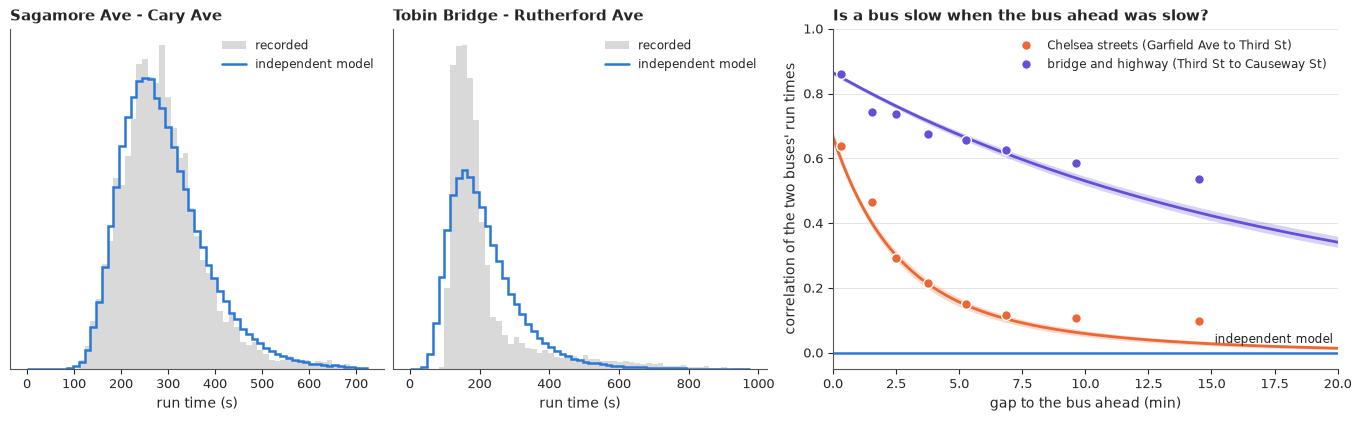

In [7]:
def residual(rows, par):
    """Log of run time over the model's median, with the posterior means of `par`."""
    k, hi = rows["k"].to_numpy(), rows["hi"].to_numpy()
    h, hl, hb = (np.minimum(rows[c].to_numpy(), 2400.0) for c in ("h", "h_lead", "h_behind"))
    tau, theta = par["tau"].mean(), par["theta"].mean()
    met = h + (0.5 * np.exp(-h / theta) * (hl - h) - 0.5 * np.exp(-hb / theta) * (h - hb) if theta > 0 else 0.0)
    return np.log(rows["run"].to_numpy()) - np.log(par["B"].mean(0)[k, hi] + tau * RATE[k, hi] * met)


chk = train_rows.assign(z=residual(train_rows, IND))
chk["z_lead"] = chk["z"].reindex(chk["lead"]).to_numpy()
chk = chk[chk["lead"] >= 0]
GAP_EDGES = np.array([0, 60, 120, 180, 270, 360, 480, 720, 2400])
gap_mid = chk.groupby(pd.cut(chk["h"], GAP_EDGES), observed=True)["h"].median().to_numpy()
GROUPS = {"Chelsea streets (Garfield Ave to Third St)": [1, 2, 3, 4], "bridge and highway (Third St to Causeway St)": [5, 6, 7]}

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1), gridspec_kw={"width_ratios": [1, 1, 1.35]})
for ax, s in zip(axes[:2], (2, 6)):
    obs = train_rows.loc[train_rows["k"] == s]
    edges = np.linspace(0, np.quantile(obs["run"], 0.995), 60)
    sim = IND["B"].mean(0)[s, obs["hi"].to_numpy()] * np.exp(IND["sigma"].mean(0)[s] * rng.normal(size=(40, len(obs))))
    ax.hist(obs["run"], bins=edges, density=True, color=LIGHT, label="recorded")
    ax.stairs(np.histogram(sim.ravel(), bins=edges, density=True)[0], edges, color=BLUE, lw=1.8, label="independent model")
    ax.set_xlabel("run time (s)")
    ax.set_yticks([])
    ax.set_title(SEG[s], loc="left", fontsize=10.5)
    ax.legend(frameon=False, fontsize=8.5)
    tidy(ax, grid=None)
ax = axes[2]
hh = np.linspace(0, 1200, 200)
for (label, segs), colour in zip(GROUPS.items(), (ORANGE, VIOLET)):
    c = chk[chk["k"].isin(segs)]
    r = [np.corrcoef(g["z"], g["z_lead"])[0, 1] for _, g in c.groupby(pd.cut(c["h"], GAP_EDGES), observed=True)]
    curve = (TRAF["rho0"][:, segs, None] * np.exp(-hh[None, None, :] / TRAF["ell"][:, segs, None])).mean(1)
    ax.fill_between(hh / 60, *np.quantile(curve, [0.05, 0.95], axis=0), color=colour, alpha=0.25, lw=0)
    ax.plot(hh / 60, curve.mean(0), color=colour, lw=2)
    ax.plot(gap_mid / 60, r, "o", ms=7, color=colour, mec="white", mew=1, label=label)
ax.axhline(0, color=BLUE, lw=1.8)
ax.text(19.8, 0.03, "independent model", color=INK, fontsize=8.5, ha="right")
ax.set_xlim(0, 20)
ax.set_ylim(-0.05, 1)
ax.set_xlabel("gap to the bus ahead (min)")
ax.set_ylabel("correlation of the two buses' run times")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.set_title("Is a bus slow when the bus ahead was slow?", loc="left", fontsize=10.5)
tidy(ax)
gap_small = chk[chk["h"] <= 120]
print("correlation with the bus ahead when it is at most 2 minutes ahead:",
      ", ".join(f"{NAME[s + 1]} {np.corrcoef(g['z'], g['z_lead'])[0, 1]:.2f}" for s, g in gap_small.groupby("k")))

Both fits are clean under nutpie: no divergences, r_hat at most 1.01, effective samples in the
thousands. With 56,000 rows the posteriors are sharp, and as in most of this notebook the
uncertainty that matters is in the shape of the model, not in its parameters.

The first two panels are the check the independent model passes. On a street segment the lognormal by
hour follows the recorded run times closely. On the bridge it is cruder: the real distribution has a
sharper peak and a longer tail, free flow on most runs and a jam on some, and one lognormal splits the
difference. We note it and go on.

The third panel is the check it fails. For every bus we take how slow it was against its hour's
median, and how slow the bus ahead had been on the same segment. The independent model says the
two are unrelated, the blue line at zero. In the records, a bus within a minute of its leader shares
its luck with a correlation of 0.6 on the streets and almost 0.9 on the bridge. On the streets the
tie is down to 0.1 within five to eight minutes. On the bridge it is still above 0.5 a quarter of an
hour later: a jam on the Tobin Bridge outlasts several buses. The traffic model reproduces both curves
with two numbers per segment, a tie for a bus right behind (0.5 to 0.8 on the streets, 0.87 on the
bridge) and a time over which it fades (two to eight minutes on the streets, a quarter of an hour to
three quarters on the bridge). The first segment, out of the terminal, shows almost none.

This matters for bunching because a gap changes by the difference between two buses' run times. If
a jam slows both, the gap does not move. Independent noise makes every jam pull neighbouring buses
apart or push them together.

> **The choice.** Run time is lognormal around a level for each segment and hour, with noise tied to
> the bus ahead by a correlation that fades with the gap between them. *Rejected:* noise that is
> independent from bus to bus (it fits the run times and misses that neighbours share them).
> *Considered:* heavier tails or a mixture for the bridge, and a latent traffic level for every day
> and hour, of which the tie to the bus ahead is a cheap stand-in that needs no hidden variable.
> *What would change our mind:* speeds of the general traffic on the same streets. They would
> replace the bus ahead as the witness, and would tell a jam from a slow bus.

## 3 · Dwell: does a longer gap make a slower bus?

Now the passenger loop. Riders arrive at stops at some rate $r$. A bus that follows its leader by
a gap $h$ meets about $r\,h$ of them, and if each takes $\tau$ seconds to board, the run time grows
by $\tau\,r\,h$. We cannot see dwell, and we cannot see riders on a given bus. What we can see is
whether a longer gap goes with a longer run time, and we know $r$ for every segment and hour from the
season's counts. So dwell is reached through two stand-ins: the gap stands in for the riders waiting,
and the extra run time stands in for the time spent boarding them.

Before fitting anything, the route offers a natural experiment. On five segments riders board, on
three hardly anyone does, and into Haymarket they only get off. If the gap matters because of
passengers, it should matter on the first five and nowhere else. For each segment we regress the run
time of a bus, minus that of the bus ahead (which removes the traffic they share), on the gap.

In [8]:
def slope(g):
    """Extra seconds of run time, against the bus ahead, per extra minute of gap; with its standard error."""
    x, y = g["h"].to_numpy() / 60, g["run"].to_numpy() - g["run_lead"].to_numpy()
    x = x - x.mean()
    b = (x * y).sum() / (x**2).sum()
    return pd.Series({"slope": b, "se": np.sqrt(((y - y.mean() - b * x) ** 2).sum() / (len(x) - 2) / (x**2).sum())})


nat = train_rows.assign(run_lead=train_rows["run"].reindex(train_rows["lead"]).to_numpy())
nat = nat[(nat["lead"] >= 0) & nat["t"].between(W0, W1)]
slopes = nat.groupby("k").apply(slope)
slopes["boardings per hour"] = RATE[:, 1:14].mean(1) * 3600
slopes.index = SEG
print(slopes.round(2).to_string())

t0 = time.time()
OWN = fit_segments(train_rows, STREETS, traffic=True, gap="own")
SHARED = fit_segments(train_rows, STREETS, traffic=True, gap="shared")
print("\n" + pd.DataFrame(DIAG[2:]).round(3).to_string(index=False), f"\n{time.time() - t0:.0f} s")
for label, par in (("own gap", OWN), ("shared in a bunch", SHARED)):
    lo, hi_ = np.quantile(par["tau"], [0.05, 0.95])
    extra = f"; a bunch is a gap under about {par['theta'].mean():.0f} s" if par["theta"].mean() > 0 else ""
    print(f"{label}: {par['tau'].mean():.1f} s per boarding rider (90% interval {lo:.1f} to {hi_:.1f}){extra}")

                               slope    se  boardings per hour
Woodlawn - Garfield Ave         5.08  0.73               40.13
Garfield Ave - Sagamore Ave     1.85  0.22               32.73
Sagamore Ave - Cary Ave         5.78  0.36               80.05
Cary Ave - Bellingham Sq        4.03  0.21               72.59
Bellingham Sq - Third St        2.48  0.23               65.15
Third St - Tobin Bridge        -0.01  0.07                0.00
Tobin Bridge - Rutherford Ave  -0.83  0.21                0.00
Rutherford Ave - Causeway St    0.40  0.22                1.67
Causeway St - Haymarket        -1.29  0.21                0.00



               model  segments  rows  divergences  max r_hat  min ESS
   traffic, gap: own         5 31074            0      1.005     2312
traffic, gap: shared         5 31074            0      1.004      851 
49 s
own gap: 1.8 s per boarding rider (90% interval 1.7 to 1.9)
shared in a bunch: 4.2 s per boarding rider (90% interval 4.0 to 4.4); a bunch is a gap under about 90 s


own gap only: run time against the model, by gap (%): [7.7, 3.1, -4.3, -5.2, -6.3, -2.5, 0.2, 4.5, 6.3]
riders shared inside a bunch: run time against the model, by gap (%): [6.4, 4.0, -1.7, -2.4, -4.2, -1.8, -0.4, 2.8, 3.3]


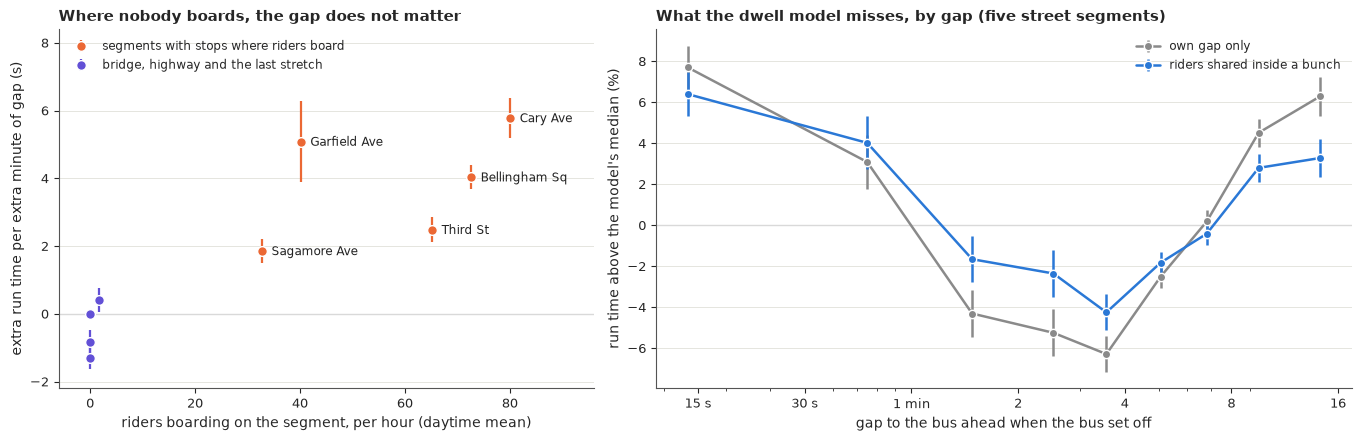

In [9]:
street_rows = train_rows[train_rows["k"] < 5]
RES_EDGES = np.array([0, 30, 60, 120, 180, 240, 360, 480, 720, 2400])
res_mid = street_rows.groupby(pd.cut(street_rows["h"], RES_EDGES), observed=True)["h"].median().to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
streets = np.arange(9) < 5
ax.axhline(0, color=LIGHT, lw=1)
for mask, colour, label in ((streets, ORANGE, "segments with stops where riders board"),
                            (~streets, VIOLET, "bridge, highway and the last stretch")):
    ax.errorbar(slopes["boardings per hour"][mask], slopes["slope"][mask], yerr=1.64 * slopes["se"][mask], fmt="o",
                ms=7, color=colour, mec="white", mew=1, elinewidth=1.6, label=label)
for s in (0, 1, 2, 3, 4):
    ax.annotate(SEG[s].split(" - ")[1], (slopes["boardings per hour"].iloc[s], slopes["slope"].iloc[s]),
                xytext=(7, -3), textcoords="offset points", fontsize=8.3, color=INK)
ax.set_xlabel("riders boarding on the segment, per hour (daytime mean)")
ax.set_ylabel("extra run time per extra minute of gap (s)")
ax.set_xlim(-6, 96)
ax.set_ylim(-2.2, 8.4)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Where nobody boards, the gap does not matter", loc="left")
tidy(ax)

ax = axes[1]
ax.axhline(0, color=LIGHT, lw=1)
for par, colour, label in ((OWN, MUTED, "own gap only"), (SHARED, BLUE, "riders shared inside a bunch")):
    z = pd.Series(residual(street_rows, par) * 100)
    cut = pd.cut(street_rows["h"].to_numpy(), RES_EDGES)
    m, se = z.groupby(cut, observed=True).mean(), z.groupby(cut, observed=True).sem()
    ax.errorbar(res_mid / 60, m, yerr=1.64 * se, fmt="o-", ms=6, color=colour, mec="white", mew=1, lw=1.8, label=label)
    print(f"{label}: run time against the model, by gap (%):", m.round(1).tolist())
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 16], ["15 s", "30 s", "1 min", "2", "4", "8", "16"])
ax.set_xlabel("gap to the bus ahead when the bus set off")
ax.set_ylabel("run time above the model's median (%)")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("What the dwell model misses, by gap (five street segments)", loc="left")
tidy(ax);

The left panel is the natural experiment. On the five street segments an extra minute of gap costs
two to six seconds of run time. On the stretch from Third St to the bridge it costs 0.0 seconds,
give or take 0.1, and on the other segments without boarding the slopes are small and of both signs
(into Haymarket a bus loses about a second for every minute by which it is closer to the bus ahead,
perhaps waiting for the kerb). Where nobody boards, the gap does not matter. The slopes are not in
strict proportion to the boardings, but the split between the two groups is as clean as one could
ask.

The first dwell model takes the theory at its word. The median run time of part 2 gains a term for
the riders gathered over the bus's **own gap**, with the boarding rate $r_{k,\text{hour}}$ taken
from the counts and one unknown, the seconds per boarding rider:

$$\text{median}_{ik} = B_{k,\text{hour}} + \tau\; r_{k,\text{hour}}\; m_{ik}, \qquad m_{ik} = h_{ik}.$$

It estimates $\tau$ at 1.8 seconds, and the grey line in the right panel shows what is wrong with
it. Buses that set off within half a minute of their leader run 8% slower than the model's median.
Buses one to four minutes behind run 4% to 6% faster, and buses more than eight minutes behind about
5% slower again. A straight line in the gap cannot bend like that, and the close followers
drag its slope down.

The reason is in the street. A bus right behind another does not meet an empty kerb and drive on.
Its leader is usually the late bus of the story, with a long gap in front of it, and the two travel
together: the follower stops where the leader does, or passes it and takes the next stop. A bunch
shares its riders. The second model says so. The riders a bus has to deal with are gathered over an
effective gap

$$m_{ik} = h_{ik} + \tfrac12 e^{-h_{ik}/\theta}\,(h_{\text{lead}} - h_{ik})
          - \tfrac12 e^{-h_{\text{behind}}/\theta}\,(h_{ik} - h_{\text{behind}}),$$

so that a bus right behind another takes half of what the pair has to pick up, its leader gives up
the same half, and $\theta$ says how close counts as a bunch. With that, $\tau$ comes out at 4.2
seconds per boarding rider (90% interval 4.0 to 4.4) and $\theta$ at about 90 seconds. Both dwell
fits are clean as well: no divergences, r_hat at most 1.01, several hundred effective samples for
the slowest parameter. The four seconds are more than one rider needs at the door: they carry
everything that comes with a boarding and that we cannot separate, the stopping, the doors, the
riders getting off.

The blue line is this model against the same check. The misfit is about halved between one and
sixteen minutes. It is not gone: followers within half a minute are still 6% slower than an even
split predicts, which fits buses that cannot always get past each other on Chelsea's streets. We keep
the model and carry that misfit into part 4, where it will show up again.

One caution belongs here. A driver who is slow falls behind, and is slow again on the next segment.
That would also make long gaps go with long run times, with no rider involved. The natural experiment
argues against it only if slow drivers are slow on the bridge too. We cannot settle this from the
records, and part 6 will ask how much of the decision rests on it.

> **The choice.** Dwell enters as seconds per boarding rider, times the riders gathered over the
> gap, with a bunch sharing them; the boarding rates come from the passenger counters. *Rejected:* no
> effect of the gap (the slopes are there on exactly the segments with boarding), and the bus's own
> gap only (close followers do not run away from their leaders). *Considered:* a fixed charge for
> every stop made, since a bus stops only where somebody waits; in a least-squares trial before this
> notebook its estimate shrank to under two seconds once sharing was in. *What would change our
> mind:* door times or rider counts per bus. And an experiment: hold some buses on purpose and see
> whether their run times follow the gap we gave them.

## 4 · Dynamics: do the pieces, put together, bunch like the real route?

Parts 2 and 3 describe one bus on one segment, given the gaps around it. Bunching is what happens
when a whole day of buses run under those rules one after another, each one's gap made by the buses
before it. We simulate that. At each timepoint the simulator puts the buses in the order they leave,
works out each one's gap and the riders it has to deal with, draws its run time with the traffic tie
to the bus ahead, and moves everybody to the next timepoint, where the order may have changed. One
replication of a day uses one draw from the posteriors of parts 2 and 3, so the uncertainty of the
parameters travels with it.

A simulator is a model like any other and has to earn trust by reproducing data, here the 18 days of
November that no fit has seen. It needs one more input, the times at which buses leave Woodlawn. The
first version takes the natural one, and the one the theory starts from: **buses leave on
schedule**, and whatever bunching there is must grow on the way.

In [10]:
@njit
def hold_back(ready, gap_by_hour, max_hold, held):
    """Buses ready to leave at `ready` wait until the bus ahead has `gap` seconds on them, at most max_hold."""
    out = ready.copy()
    last = -1e9
    for i in np.argsort(ready):
        gap = gap_by_hour[min(max(int(ready[i] // 3600) - H0, 0), NH - 1)]
        if ready[i] - last < gap:
            out[i] = min(last + gap, ready[i] + max_hold)
            held[i] += out[i] - ready[i]
        last = max(last, out[i])
    return out


@njit
def simulate(start, B, rate, tau, theta, sigma, rho0, ell, eps, hold_k, gap_by_hour, max_hold):
    """One day of buses down the route, for one posterior draw. start: when each bus is ready to leave
    the terminal. eps: one standard normal per bus and segment. Returns the departures from the ten
    timepoints and the seconds each bus was held (at timepoint hold_k; -1 for no holding)."""
    n = len(start)
    dep = np.empty((n, 10))
    held = np.zeros(n)
    dep[:, 0] = hold_back(start, gap_by_hour, max_hold, held) if hold_k == 0 else start
    h = np.empty(n)
    for k in range(9):
        order = np.argsort(dep[:, k])
        h[0] = 360.0
        for j in range(1, n):
            h[j] = dep[order[j], k] - dep[order[j - 1], k]
        z_prev = 0.0
        for j in range(n):
            i = order[j]
            hi = min(max(int(dep[i, k] // 3600) - H0, 0), NH - 1)
            met = h[j]                                       # the gap over which this bus's riders gathered
            if theta > 0.0 and j > 0:
                met += 0.5 * np.exp(-h[j] / theta) * (h[j - 1] - h[j])
            if theta > 0.0 and j < n - 1:
                met -= 0.5 * np.exp(-h[j + 1] / theta) * (h[j] - h[j + 1])
            rho = rho0[k] * np.exp(-h[j] / ell[k]) if j > 0 else 0.0
            z = rho * z_prev + np.sqrt(1.0 - rho * rho) * sigma[k] * eps[i, k]
            dep[i, k + 1] = dep[i, k] + (B[k, hi] + tau * rate[k, hi] * min(met, 2400.0)) * np.exp(z)
            z_prev = z
        if hold_k == k + 1:
            dep[:, k + 1] = hold_back(dep[:, k + 1].copy(), gap_by_hour, max_hold, held)
    return dep, held


def on_route(street, rest=None):
    """Parameters for all nine segments: a fit of the five street segments, completed with `rest`."""
    rest = TRAF if rest is None else rest
    out = {v: np.concatenate([street[v], rest[v][:, 5:]], axis=1) for v in ("B", "sigma", "rho0", "ell")}
    return {**out, "tau": street["tau"], "theta": street["theta"]}


NO_HOLD = (-1, np.zeros(NH), 0.0)


def play(par, dates, rep, starts="real", rule=NO_HOLD):
    """Replication number `rep` of the given days: posterior draw `rep`, and noise that depends only on
    `rep` and the day, so that two models or two rules are compared on the same luck."""
    j = rep % N_POST
    for d in dates:
        dep, seen, sched = DAYS[d]
        eps = np.random.default_rng([RANDOM_SEED, rep, d.dayofyear]).normal(size=(len(dep), 9))
        start = np.ascontiguousarray(dep[:, 0]) if starts == "real" else sched
        sim, held = simulate(start, par["B"][j], RATE, par["tau"][j], par["theta"][j], par["sigma"][j], par["rho0"][j],
                             par["ell"][j], eps, *rule)
        yield sim, seen if starts == "real" else np.ones_like(seen), held


def replicate(par, dates, reps, **kw):
    return np.array([route_stats([(s, m) for s, m, _ in play(par, dates, r, **kw)]) for r in range(reps)])


t0 = time.time()
REPS = 40
real_test = route_stats([DAYS[d][:2] for d in TEST])
MODELS = {"independent segments": IND, "+ traffic shared with the bus ahead": TRAF,
          "+ dwell from the bus's own gap": on_route(OWN), "+ riders shared inside a bunch": on_route(SHARED)}
KEPT = MODELS["+ riders shared inside a bunch"]
on_schedule = replicate(KEPT, TEST, REPS, starts="sched")
print(f"first simulator, every bus leaving Woodlawn on schedule ({len(TEST)} November days, {REPS} replications):")
first = pd.DataFrame({f"{NAME[k]}, {what}": arr[k] for k in (0, 5, 9)
                      for what, arr in (("recorded", real_test), ("simulated", on_schedule.mean(0)))}, index=STAT_NAMES)
print(first.round(3).T.to_string())

first simulator, every bus leaving Woodlawn on schedule (18 November days, 40 replications):
                      sd / mean of the gap  gaps under 1 min  gaps over 12 min  mean wait (min)
Woodlawn, recorded                   0.732             0.072             0.089            4.636
Woodlawn, simulated                  0.282             0.000             0.004            3.158
Third St, recorded                   0.957             0.223             0.131            5.795
Third St, simulated                  0.674             0.105             0.065            4.230
Haymarket, recorded                  0.947             0.165             0.132            5.697
Haymarket, simulated                 0.732             0.116             0.086            4.462


### Failure: buses that leave on schedule

The simulated route is twice as orderly as the real one. At Third St 10% of its gaps are under a
minute where the records have 22%, and its riders wait 4.2 minutes where the real ones waited 5.8.
The first two rows say where to look. On schedule, no bus leaves Woodlawn within a minute of
another. In the records 7% do.

This is the orange arrow of the route map. Nothing in parts 2 and 3 is wrong. The chain was missing
a link that nobody would have listed at the start, because it is not about how buses run at all:
**how they leave the terminal**.

### The link we had not planned: departures from Woodlawn

gaps between departures from Woodlawn, scheduled: mean 5.7 min, sd/mean 0.22; recorded: mean 5.8 min, sd/mean 0.68, under a minute 7.5%, over twelve 7.1%
departure against the timetable: median 25 s late; more than 3 minutes late 24.0%; more than a minute early 6.0%


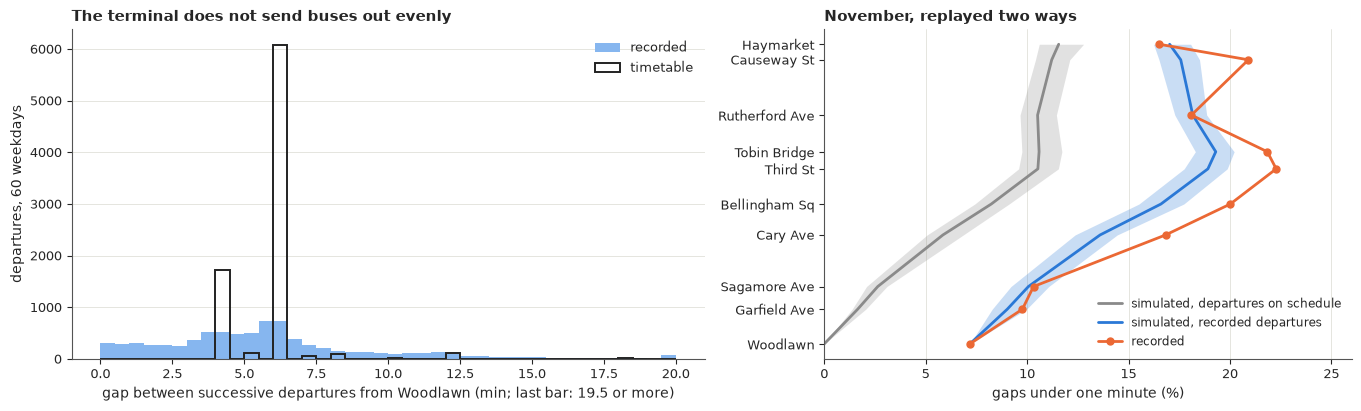

In [11]:
def daytime_gaps(t):
    t = np.sort(t)
    return np.diff(t)[(t[1:] >= W0) & (t[1:] < W1)]


sched_gaps = np.concatenate([daytime_gaps(DAYS[d][2]) for d in DAYS])
real_gaps = np.concatenate([gaps_at(*DAYS[d][:2], 0) for d in DAYS])
late = np.concatenate([(dep[:, 0] - sched)[seen[:, 0] & (sched >= W0) & (sched < W1)] for dep, seen, sched in DAYS.values()])
print(f"gaps between departures from Woodlawn, scheduled: mean {sched_gaps.mean() / 60:.1f} min, sd/mean "
      f"{sched_gaps.std() / sched_gaps.mean():.2f}; recorded: mean {real_gaps.mean() / 60:.1f} min, sd/mean "
      f"{real_gaps.std() / real_gaps.mean():.2f}, under a minute {(real_gaps < 60).mean():.1%}, over twelve "
      f"{(real_gaps > 720).mean():.1%}")
print(f"departure against the timetable: median {np.median(late):.0f} s late; more than 3 minutes late "
      f"{(late > 180).mean():.1%}; more than a minute early {(late < -60).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.0), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
edges = np.arange(0, 20.01, 0.5)
ax.hist(np.clip(real_gaps / 60, 0, 19.99), bins=edges, color="#86b6ef", label="recorded")
ax.hist(sched_gaps / 60, bins=edges, histtype="step", color=INK, lw=1.4, label="timetable")
ax.set_xlabel("gap between successive departures from Woodlawn (min; last bar: 19.5 or more)")
ax.set_ylabel("departures, 60 weekdays")
ax.legend(frameon=False, fontsize=9)
ax.set_title("The terminal does not send buses out evenly", loc="left")
tidy(ax)
ax = axes[1]
start_stats = replicate(KEPT, TEST, REPS)
for arr, colour, label in ((on_schedule, MUTED, "simulated, departures on schedule"),
                           (start_stats, BLUE, "simulated, recorded departures")):
    ax.fill_betweenx(Y_MIN, *np.quantile(arr[:, :, 1], [0.05, 0.95], axis=0) * 100, color=colour, alpha=0.25, lw=0)
    ax.plot(arr[:, :, 1].mean(0) * 100, Y_MIN, color=colour, lw=2, label=label)
ax.plot(real_test[:, 1] * 100, Y_MIN, "o-", color=ORANGE, lw=2, ms=5, label="recorded")
ax.set_yticks(Y_MIN, NAME)
ax.set_xlim(0, 26)
ax.set_xlabel("gaps under one minute (%)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("November, replayed two ways", loc="left")
tidy(ax, grid="x");

The timetable asks for a bus every four minutes until 8:00 and every six after that. The recorded
gaps have the right mean, 5.8 minutes, and nothing else: their standard deviation is two thirds of
their mean, where the timetable's is a fifth. One departure in thirteen follows the previous bus
by less than a minute, and one in fourteen by more than twelve. The median bus leaves 25 seconds late,
a quarter leave more than three minutes late, and a few leave early. We suppose a bus leaves late
when it came in late from its trip out, and the next one leaves on time just behind it, but the
records do not link one trip of a vehicle to its next, so this stays a supposition.

So from here on a replay starts every bus from Woodlawn at the moment it really left, and simulates
everything after that. In the right panel the simulator started this way (blue) climbs with the
records (orange) instead of running at half their level.

### Four simulators on the same November

With the start settled we can test the proposal properly. We replay November with four simulators,
adding one ingredient at a time: independent segments (part 2's first model), traffic shared with the
bus ahead, dwell from the bus's own gap, and riders shared inside a bunch. Each is replayed 40
times.

In [12]:
CHANGE_EDGES = np.array([0, 30, 60, 120, 180, 240, 360, 480, 720, 2400])


def gap_changes(days):
    """What happens to a gap over one street segment, by its size: mean change (s), share of followers
    that overtake, share of pairs still within a minute of each other."""
    h, ch = [], []
    for dep, seen in days:
        for k in range(5):
            o = np.argsort(dep[:, k])
            real = seen[o, k] & seen[o, k + 1]
            ok = real[1:] & real[:-1] & (dep[o[1:], k] >= W0) & (dep[o[1:], k] < W1)
            h.append(np.diff(dep[o, k])[ok])
            ch.append(np.diff(dep[o, k + 1])[ok] - h[-1])
    h, ch = np.concatenate(h), np.concatenate(ch)
    b = np.digitize(h, CHANGE_EDGES) - 1
    return np.array([[ch[b == i].mean(), (h + ch < 0)[b == i].mean(), (np.abs(h + ch) < 60)[b == i].mean()]
                     for i in range(len(CHANGE_EDGES) - 1)])


def spread_of_trips(days):
    run = np.concatenate([(dep[:, 9] - dep[:, 0])[seen[:, 0] & seen[:, 9] & (dep[:, 0] >= W0) & (dep[:, 0] < W1)]
                          for dep, seen in days])
    return run.std() / 60


ladder, changes, trip_sd = {}, {}, {}
for name, par in MODELS.items():
    sims = [[(s, m) for s, m, _ in play(par, TEST, r)] for r in range(REPS)]
    ladder[name] = np.array([route_stats(x) for x in sims])
    changes[name] = np.array([gap_changes(x) for x in sims])
    trip_sd[name] = np.mean([spread_of_trips(x) for x in sims])
real_changes = gap_changes([DAYS[d][:2] for d in TEST])
print(f"four simulators replayed on {len(TEST)} November days in {time.time() - t0:.0f} s; at Third St and at Haymarket:")
rows = {"recorded": np.r_[real_test[5], real_test[9]]}
rows.update({name: np.r_[v.mean(0)[5], v.mean(0)[9]] for name, v in ladder.items()})
print(pd.DataFrame(rows, index=pd.MultiIndex.from_product([["Third St", "Haymarket"], STAT_NAMES])).T.round(3).to_string())
short = pd.DataFrame({"recorded": real_changes[0]} | {n: v.mean(0)[0] for n, v in changes.items()},
                     index=["change of the gap (s)", "follower overtakes", "still within a minute"]).T
print("\nbuses that set off less than 30 s behind another, one street segment later:")
print(short.round(2).to_string())
print(f"\nsd of the whole trip, Woodlawn to Haymarket (min): recorded "
      f"{spread_of_trips([DAYS[d][:2] for d in TEST]):.1f}; simulated", ", ".join(f"{v:.1f}" for v in trip_sd.values()))

four simulators replayed on 18 November days in 4 s; at Third St and at Haymarket:
                                                Third St                                                              Haymarket                                                  
                                    sd / mean of the gap gaps under 1 min gaps over 12 min mean wait (min) sd / mean of the gap gaps under 1 min gaps over 12 min mean wait (min)
recorded                                           0.957            0.223            0.131           5.795                0.947            0.165            0.132           5.697
independent segments                               0.803            0.101            0.098           4.969                0.803            0.115            0.109           4.951
+ traffic shared with the bus ahead                0.823            0.118            0.104           5.070                0.832            0.130            0.115           5.086
+ dwell from the bus's own 

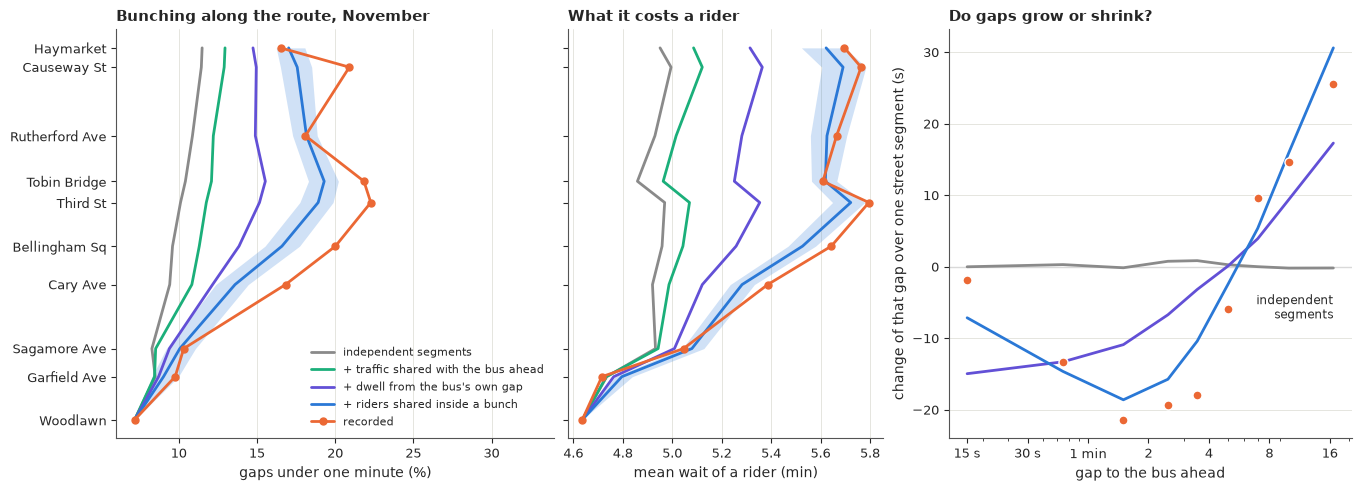

In [13]:
COLOURS = {"independent segments": MUTED, "+ traffic shared with the bus ahead": AQUA,
           "+ dwell from the bus's own gap": VIOLET, "+ riders shared inside a bunch": BLUE}
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.25, 0.9, 1.15]})
for ax, j, label in ((axes[0], 1, "gaps under one minute (%)"), (axes[1], 3, "mean wait of a rider (min)")):
    scale = 100 if j == 1 else 1
    for name, arr in ladder.items():
        if name == "+ riders shared inside a bunch":
            ax.fill_betweenx(Y_MIN, *np.quantile(arr[:, :, j], [0.05, 0.95], axis=0) * scale, color=BLUE, alpha=0.22, lw=0)
        ax.plot(arr[:, :, j].mean(0) * scale, Y_MIN, color=COLOURS[name], lw=2, label=name)
    ax.plot(real_test[:, j] * scale, Y_MIN, "o-", color=ORANGE, lw=2, ms=5, label="recorded")
    ax.set_yticks(Y_MIN, NAME if j == 1 else [])
    ax.set_xlabel(label)
    tidy(ax, grid="x")
axes[0].set_title("Bunching along the route, November", loc="left")
axes[1].set_title("What it costs a rider", loc="left")
axes[0].set_xlim(6, 34)
axes[0].legend(frameon=False, fontsize=8.2, loc="lower right")
ax = axes[2]
mid = np.array([15, 45, 90, 150, 210, 300, 420, 600, 1000]) / 60
ax.axhline(0, color=LIGHT, lw=1)
for name in ("independent segments", "+ dwell from the bus's own gap", "+ riders shared inside a bunch"):
    ax.plot(mid, changes[name].mean(0)[:, 0], color=COLOURS[name], lw=2)
ax.plot(mid, real_changes[:, 0], "o", color=ORANGE, ms=6.5, mec="white", mew=1)
ax.text(mid[-1], changes["independent segments"].mean(0)[-1, 0] - 3.5, "independent\nsegments", fontsize=8.3, ha="right", va="top")
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 16], ["15 s", "30 s", "1 min", "2", "4", "8", "16"])
ax.set_xlabel("gap to the bus ahead")
ax.set_ylabel("change of that gap over one street segment (s)")
ax.set_title("Do gaps grow or shrink?", loc="left")
tidy(ax);

**Independent segments do produce bunches.** The proposal said they never could. Started from the
real departures, the independent simulator has 10% of gaps under a minute at Third St, against 7% at
Woodlawn: run times that vary let gaps wander, and some wander to zero. What it cannot do is produce
enough of them. The real figure is 22%, so noise accounts for about three of the fifteen points that
bunching gains between Woodlawn and Third St.

**Each ingredient brings the simulator closer.** Traffic takes it to 12%, dwell from the bus's own
gap to 15%, and sharing inside a bunch to 19%. With all of them the spread of the gaps at Third St
(standard deviation over mean) is 0.94 against 0.96 and the mean wait 5.7 minutes against 5.8, and
at Haymarket 17% of gaps are under a minute against 16.5%. The band around the blue line is the
spread over replications, and it is narrow: between Cary Ave and Third St the records sit three
points outside it. The simulator still makes too few bunches on the streets.

**The right panel shows why noise is not enough.** Take all the gaps of a given size and see what
has happened to them one street segment later. In the records (orange) gaps shorter than about five
minutes shrink, by up to twenty seconds per segment, and gaps longer than about six minutes grow.
The even gap is a ridge, and a bus that slides off it keeps sliding. Only the very short gaps stay
as they are: a bunch is where the sliding ends. Under independent segments (grey) nothing slides. A
gap is as likely to grow as to shrink whatever its size, and bunches happen by accident. That is the
part of the proposal that holds: without the passenger loop there is no force. With dwell from the
bus's own gap (violet) the force has the right sign and the wrong shape at the short end, where
simulated followers close in at fifteen seconds per segment and drive through their leaders. With
sharing (blue) the curve bends back as the records do.

The short table above puts numbers on that end. Of the real buses that set off less than half a
minute behind another, 27% have overtaken it by the next timepoint and 82% are still within a minute
of it. In the simulator we keep, 44% overtake and 74% stay close: its bunches swap places too
easily, the misfit of part 3 again. A rider at the stop does not care which of two buses is in
front, so we let it stand.

The other way to draw the instability uses both gaps of a bus at once.

          recorded: mean movement (ahead, behind) in min, from 8-10 ahead and 2-4 behind: [-1.43 -0.  ]; from 2-4 ahead and 8-10 behind: [0.17 0.44]; from 4-6 on both sides: [-0.28 -0.07]
       noise alone: mean movement (ahead, behind) in min, from 8-10 ahead and 2-4 behind: [-1.64  1.14]; from 2-4 ahead and 8-10 behind: [ 0.99 -1.42]; from 4-6 on both sides: [-0.07 -0.04]
 simulator we keep: mean movement (ahead, behind) in min, from 8-10 ahead and 2-4 behind: [-1.39  0.36]; from 2-4 ahead and 8-10 behind: [ 0.8  -0.47]; from 4-6 on both sides: [ 0.03 -0.13]


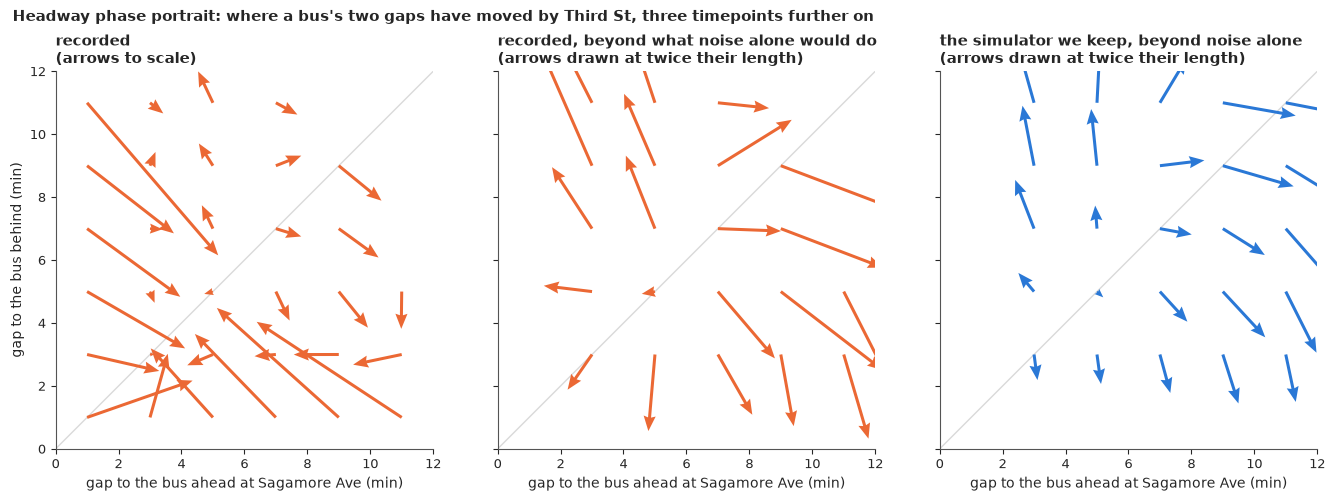

In [14]:
def portrait(days, k0=2, k1=5, cells=6, top=720.0):
    """Mean movement of a bus in the plane (gap ahead, gap behind) between timepoints k0 and k1."""
    sums, count = np.zeros((cells, cells, 2)), np.zeros((cells, cells))
    for dep, seen in days:
        ahead, behind = [], []
        for k in (k0, k1):
            o = np.argsort(dep[:, k])
            g = np.full(len(o) + 1, np.nan)
            g[1:-1] = np.diff(dep[o, k])
            a, b = np.empty(len(o)), np.empty(len(o))
            a[o], b[o] = g[:-1], g[1:]
            ahead.append(a), behind.append(b)
        ok = seen[:, k0] & seen[:, k1] & (dep[:, k0] >= W0) & (dep[:, k0] < W1) & (ahead[0] < top) & (behind[0] < top)
        i, j = (ahead[0][ok] // (top / cells)).astype(int), (behind[0][ok] // (top / cells)).astype(int)
        np.add.at(sums, (i, j, 0), (ahead[1] - ahead[0])[ok])
        np.add.at(sums, (i, j, 1), (behind[1] - behind[0])[ok])
        np.add.at(count, (i, j), 1)
    return np.where(count[:, :, None] >= 40, sums / np.maximum(count, 1)[:, :, None], np.nan) / 60


every_day = list(DAYS)
field_real = portrait([DAYS[d][:2] for d in every_day])
field_noise = portrait([(s, m) for r in range(4) for s, m, _ in play(IND, every_day, r)])
field_kept = portrait([(s, m) for r in range(4) for s, m, _ in play(KEPT, every_day, r)])
room = np.full((6, 6, 1), np.nan)
room[1:, 1:] = 1.0                                   # cells where both gaps are at least two minutes
flows = {"recorded": (field_real, ORANGE, 1.0),
         "recorded, beyond what noise alone would do": ((field_real - field_noise) * room, ORANGE, 0.5),
         "the simulator we keep, beyond noise alone": ((field_kept - field_noise) * room, BLUE, 0.5)}
centres = (np.arange(6) + 0.5) * 2.0
gx, gy = np.meshgrid(centres, centres, indexing="ij")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.9), sharex=True, sharey=True)
for ax, (title, (flow, colour, scale)) in zip(axes, flows.items()):
    ax.plot([0, 12], [0, 12], color=LIGHT, lw=1, zorder=0)
    ax.quiver(gx, gy, flow[:, :, 0], flow[:, :, 1], angles="xy", scale_units="xy", scale=scale, color=colour, width=0.008,
              headwidth=4, headlength=5)
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 12)
    ax.set_aspect("equal")
    ax.set_xticks(range(0, 13, 2))
    ax.set_yticks(range(0, 13, 2))
    ax.set_xlabel("gap to the bus ahead at Sagamore Ave (min)")
    ax.set_title(title + ("" if scale == 1 else "\n(arrows drawn at twice their length)"), loc="left", fontsize=10.5)
    tidy(ax, grid=None)
axes[0].set_title("recorded\n(arrows to scale)", loc="left", fontsize=10.5)
axes[0].set_ylabel("gap to the bus behind (min)")
fig.suptitle("Headway phase portrait: where a bus's two gaps have moved by Third St, three timepoints further on",
             x=0.01, ha="left", fontsize=11)
for label, f in (("recorded", field_real), ("noise alone", field_noise), ("simulator we keep", field_kept)):
    print(f"{label:>18}: mean movement (ahead, behind) in min, from 8-10 ahead and 2-4 behind: {f[4, 1].round(2)}; "
          f"from 2-4 ahead and 8-10 behind: {f[1, 4].round(2)}; from 4-6 on both sides: {f[2, 2].round(2)}");

A **headway phase portrait**. Every bus has a gap in front of it and a gap behind it, so it is a
point in this plane, and perfectly even service puts every bus at one point on the diagonal. An
arrow starts where a group of buses was at Sagamore Ave and ends where the same buses were, on
average, three timepoints later at Third St.

The left panel is the records as they are, and at first sight it shows the opposite of an
instability: the long arrows point inwards. That is the edge of the plane at work. A gap cannot be
less than zero, so a very short gap can only open, and when a bus is overtaken its "bus ahead"
becomes a different bus. Noise alone does all of that. So for the other two panels we subtract what
the independent-segments simulator does from the same starting point, and look at what is left
where both gaps are at least two minutes.

What is left is the loop. Below the diagonal are the late buses, with more room ahead than behind,
and their arrows point right and down: the gap ahead grows and the gap behind shrinks. Above it
are the buses catching up, and their arrows point up and left. Everything moves away from the
diagonal. In numbers: a bus with eight to ten minutes ahead of it and two to four behind would, by
noise alone, see its long gap shrink by 1.6 minutes and its short gap open by 1.1. In the records
the long gap shrinks by 1.4 and the short gap does not open at all. The simulator we keep (right)
shows the same field, a little weaker behind the bus.

The last look at the simulator is the time-space diagram again, with the models' uncertainty drawn
in.

median width of a ribbon at Haymarket: 11 min
share of recorded readings inside the 80% ribbon, by timepoint, all November days: Garfield Ave 0.86, Sagamore Ave 0.79, Cary Ave 0.72, Bellingham Sq 0.67, Third St 0.67, Tobin Bridge 0.66, Rutherford Ave 0.62, Causeway St 0.59, Haymarket 0.62
share of recorded gaps at Third St inside the simulator's 80% interval for that bus's gap: 0.73


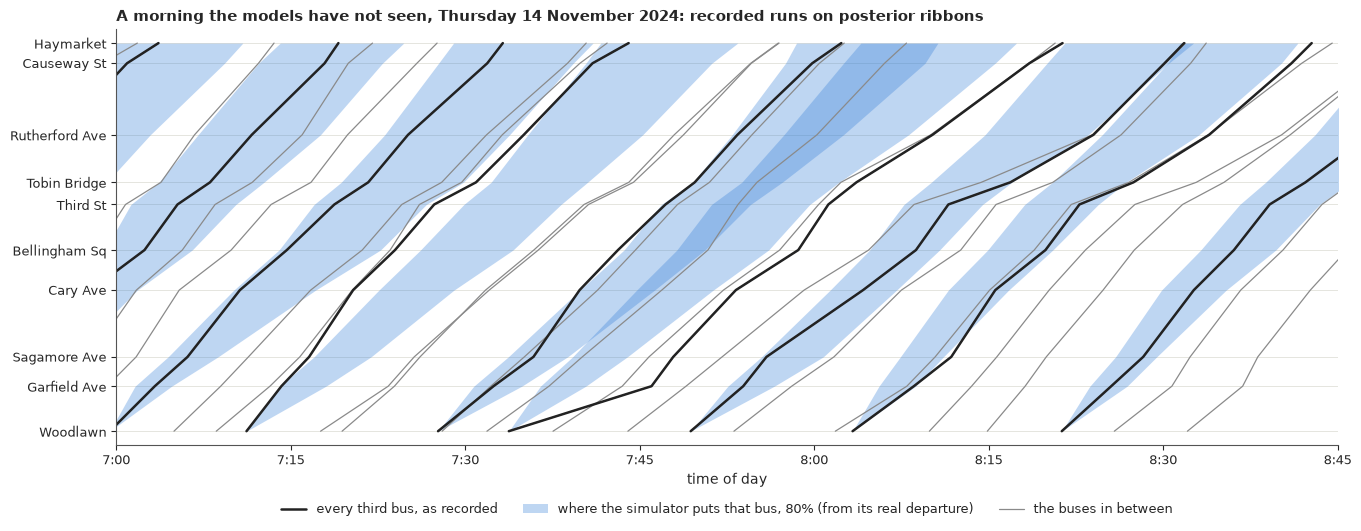

In [15]:
RIBBON_DAY, R0, R1 = TEST[8], 7.0 * 3600, 8.75 * 3600
dep_r, seen_r, _ = DAYS[RIBBON_DAY]
sims_r = np.array([next(play(KEPT, [RIBBON_DAY], r))[0] for r in range(200)])
lo, hi_ = np.quantile(sims_r, [0.1, 0.9], axis=0)
fig, ax = plt.subplots(figsize=(13.5, 5.2))
on = np.where((dep_r[:, 0] > R0 - 1500) & (dep_r[:, 0] < R1 - 600))[0]
on = on[np.argsort(dep_r[on, 0])]
marey(ax, dep_r[on], seen_r[on], R0, R1, colour=MUTED, lw=0.9, dots=False)
for i in on[::3]:
    ax.fill_betweenx(Y_MIN, lo[i] / 3600, hi_[i] / 3600, color=BLUE, alpha=0.3, lw=0)
    ax.plot(dep_r[i] / 3600, Y_MIN, color=INK, lw=1.8)
ax.plot([], [], color=INK, lw=1.8, label="every third bus, as recorded")
ax.fill_between([], [], [], color=BLUE, alpha=0.3, lw=0, label="where the simulator puts that bus, 80% (from its real departure)")
ax.plot([], [], color=MUTED, lw=0.9, label="the buses in between")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3)
ax.set_xlabel("time of day")
ax.set_title(f"A morning the models have not seen, {RIBBON_DAY:%A %d %B %Y}: recorded runs on posterior ribbons", loc="left")
cover, gap_cover = [], []
for d in TEST:
    dep_d, seen_d, _ = DAYS[d]
    s_ = np.array([next(play(KEPT, [d], r))[0] for r in range(60)])
    q_lo, q_hi = np.quantile(s_, [0.1, 0.9], axis=0)
    ok = seen_d & (dep_d[:, [0]] >= W0) & (dep_d[:, [0]] < W1)
    cover.append((((dep_d >= q_lo) & (dep_d <= q_hi)) & ok).sum(0) / ok.sum(0))
    ahead = lambda x: x[:, 5] - np.array([x[x[:, 5] < t, 5].max(initial=-np.inf) for t in x[:, 5]])  # gap at Third St
    g_lo, g_hi = np.quantile(np.array([ahead(x) for x in s_]), [0.1, 0.9], axis=0)
    g_real = ahead(dep_d)
    gap_cover.append(((g_real >= g_lo) & (g_real <= g_hi))[ok[:, 5] & np.isfinite(g_real)].mean())
print(f"median width of a ribbon at Haymarket: {np.median((hi_ - lo)[on, 9]) / 60:.0f} min")
print("share of recorded readings inside the 80% ribbon, by timepoint, all November days:",
      ", ".join(f"{n} {c:.2f}" for n, c in zip(NAME[1:], np.mean(cover, axis=0)[1:])))
print(f"share of recorded gaps at Third St inside the simulator's 80% interval for that bus's gap: {np.mean(gap_cover):.2f}")

Each blue ribbon is where the simulator puts one bus, 80% of the time, when that bus and all the
others leave Woodlawn as they really did. A ribbon starts as a point and fans out along the route,
to more than ten minutes at Haymarket: this is what the chain of models knows about a single bus
half an hour ahead. The black lines are what the buses did.

The ribbons are right that a single bus is not predictable: a model that bunches correctly on
average cannot say which buses will form the bunch. But they are too narrow. If they were right, 80%
of real readings would fall inside. It is 86% at Garfield Ave, 72% at Cary Ave, 67% at Third St and
62% at Haymarket, and the standard deviation of a whole trip is 5.2 minutes in the simulator against
7.9 in the records. For the gap of each bus at Third St, 73% of the real ones fall inside the
simulator's 80% interval. No check on a single segment showed this, because every segment model
matched the spread of its own run times. What the models have not been told is that the same bus is
slow on one segment after another: some days the bridge is slow for everybody, which moves no gap,
and buses and drivers have a pace of their own, which does. So the simulator's gaps, tested above,
are close in the aggregate and somewhat too sure bus by bus.

> **The choice.** A simulator of the whole day, started from the recorded departures, with free
> overtaking, traffic from part 2 and shared dwell from part 3. *Rejected:* departures on schedule (a
> route with half the bunching of the real one), independent segments (bunches by accident only:
> 10% where the street has 22%, and no drift in any gap), and dwell from the bus's own gap
> (followers that drive through their leaders). *Considered:* keeping a follower behind its leader
> unless it overtakes with some probability, which in a trial before this notebook bunched too much,
> 27% at Third St; and a pace for each bus, left as an exercise. *What would change our mind:*
> knowing which vehicle ran which trip. It would show whether late departures are late arrivals, and
> let the simulator run the loop all the way round.

## 5 · The decision: where to hold, and for how long?

The planner's remedy is to hold buses back. We give the rule one form with two dials: at one chosen
timepoint, a bus may not leave until the bus ahead has a head start of at least a share $\alpha$ of
the timetable's gap (four minutes before 8:00, six after), and no bus is held longer than five
minutes.

A rule is judged in **rider time**, in two parts. *Waiting:* riders arrive evenly at each stop, at
the season's average rate for the hour, so a gap of $h$ gathers $r\,h$ riders who have waited
$h/2$ on average, and long gaps count twice. *Riding:* each bus carries the riders it has picked
up, a share of them get off on each segment as in the season's counts, and everyone on board sits
through whatever the bus does, including being held. Both are in minutes per rider, a minute of
waiting worth a minute of riding. The accounting is as good as its assumption that riders arrive
evenly at the average rate, which is all the counts can support.

The counterfactual is a replay. We run November with and without the rule, from the same moments
at which buses were ready to leave Woodlawn and with the same luck for every bus on every segment,
so that the two runs differ by the rule alone.

In [16]:
seg_on = rin[rin["seg"] >= 0].groupby("seg")["boardings"].sum().reindex(range(9), fill_value=0.0).to_numpy()
seg_off = rin[rin["seg"] >= 0].groupby("seg")["alightings"].sum().reindex(range(9), fill_value=0.0).to_numpy()
on_board = np.r_[rin.loc[rin["seg"] < 0, "boardings"].sum(), np.zeros(9)]
LEAVE = np.zeros(9)                                  # share of those on board who get off within each segment
for k in range(9):
    LEAVE[k] = seg_off[k] / (on_board[k] + seg_on[k])
    on_board[k + 1] = on_board[k] + seg_on[k] - seg_off[k]
sched_gap = np.concatenate([np.diff(np.sort(DAYS[d][2])) for d in DAYS])
sched_hour = np.concatenate([np.sort(DAYS[d][2])[1:] // 3600 for d in DAYS]).astype(int)
SCHED_GAP = np.array([np.median(sched_gap[sched_hour == hr]) for hr in hours])       # timetable gap, by hour


@njit
def rider_time(dep, held, hold_k, rate0, rate, leave):
    """Rider-seconds spent waiting at stops and riding, and the number of riders, for the buses that leave
    the terminal between 6:00 and 19:00. Riders arrive evenly, at the season's average rate for the hour."""
    n = len(dep)
    load = np.zeros(n)
    wait = ride = riders = 0.0
    for k in range(9):
        order = np.argsort(dep[:, k])
        for j in range(n):
            i = order[j]
            if dep[i, 0] < W0 or dep[i, 0] >= W1:
                continue
            gap = min(dep[i, k] - dep[order[j - 1], k], 2400.0) if j > 0 else 360.0
            hi = min(max(int(dep[i, k] // 3600) - H0, 0), NH - 1)
            if k == 0:                                   # riders who board at the terminal itself
                load[i] = rate0[hi] * gap
                wait += load[i] * gap / 2
                riders += load[i]
            board = rate[k, hi] * gap
            wait += board * gap / 2
            riders += board
            stay = held[i] if hold_k == k + 1 else 0.0
            ride += (load[i] + board / 2) * (dep[i, k + 1] - stay - dep[i, k])
            load[i] = (load[i] + board) * (1.0 - leave[k])
            ride += load[i] * stay
    return wait, ride, riders


def rule(k, alpha, max_hold=300.0):
    """Hold at timepoint k until the bus ahead has alpha times the timetable's gap on us; never over max_hold."""
    return (k, alpha * SCHED_GAP, max_hold)


def evaluate(par, dates, reps, rule_=NO_HOLD, starts="real"):
    """Minutes of waiting and of riding per rider, seconds held per bus, the share of gaps under a minute
    at Third St, and riders per day; one row per replication."""
    out = np.empty((reps, 5))
    for r in range(reps):
        tot, held_s, buses, sims = np.zeros(3), 0.0, 0, []
        for sim, mask, held in play(par, dates, r, starts=starts, rule=rule_):
            tot += rider_time(sim, held, rule_[0], RATE0, RATE, LEAVE)
            day = (sim[:, 0] >= W0) & (sim[:, 0] < W1)
            held_s, buses = held_s + held[day].sum(), buses + day.sum()
            sims.append((sim, np.ones_like(mask)))
        out[r] = (tot[0] / tot[2] / 60, tot[1] / tot[2] / 60, held_s / buses, route_stats(sims)[5, 1],
                  tot[2] / len(dates))
    return out


t0 = time.time()
base = evaluate(KEPT, TEST, REPS)
RIDERS, BUSES = base[:, 4].mean(), np.mean([((DAYS[d][0][:, 0] >= W0) & (DAYS[d][0][:, 0] < W1)).sum() for d in TEST])
print(f"per weekday, 6:00 to 19:00: {BUSES:.0f} buses and about {RIDERS:,.0f} riders at the season's average rates; "
      f"no holding: wait {base[:, 0].mean():.2f} min, ride {base[:, 1].mean():.2f} min per rider, "
      f"{base[:, 3].mean():.1%} of gaps under a minute at Third St")
ALPHAS = [0.5, 0.75, 1.0]
menu = {}
for k in range(6):
    for a in ALPHAS:
        menu[(k, a)] = evaluate(KEPT, TEST, REPS, rule(k, a)) - base
table = pd.DataFrame({key: [v[:, 0].mean(), v[:, 1].mean(), v[:, :2].sum(1).mean(), (v[:, :2].sum(1) < 0).mean(),
                            (v[:, 2] + base[:, 2]).mean(), v[:, 3].mean() * 100] for key, v in menu.items()},
                     index=["wait (min per rider)", "ride (min per rider)", "total (min per rider)",
                            "P(total falls)", "held per bus (s)", "bunched at Third St (points)"]).T
table.index = [f"{NAME[k]}, {a:.2f}" for k, a in menu]
print(f"\nchange against no holding, {len(menu)} rules in {time.time() - t0:.0f} s (rule: where, and the share of "
      "the timetable gap it insists on):")
print(table.round(3).to_string())

per weekday, 6:00 to 19:00: 132 buses and about 4,047 riders at the season's average rates; no holding: wait 4.53 min, ride 17.45 min per rider, 20.0% of gaps under a minute at Third St



change against no holding, 18 rules in 4 s (rule: where, and the share of the timetable gap it insists on):
                     wait (min per rider)  ride (min per rider)  total (min per rider)  P(total falls)  held per bus (s)  bunched at Third St (points)
Woodlawn, 0.50                     -0.163                -0.001                 -0.164           1.000            27.757                        -2.420
Woodlawn, 0.75                     -0.381                -0.034                 -0.415           1.000            66.843                        -4.937
Woodlawn, 1.00                     -0.660                -0.100                 -0.760           1.000           174.625                        -6.631
Garfield Ave, 0.50                 -0.208                 0.052                 -0.156           1.000            31.336                        -4.599
Garfield Ave, 0.75                 -0.461                 0.128                 -0.334           1.000            76.813                

terminal dial in 5 s; rider time is lowest at 1.12 of the timetable gap:
 share of timetable gap   wait   ride  total  held per bus (s)  bunched at Third St (points)  rider-hours saved a day  bus-hours held a day
                  0.000  0.000  0.000  0.000             0.000                         0.000                   -0.000                 0.000
                  0.125 -0.004  0.001 -0.002             1.415                        -0.024                    0.157                 0.052
                  0.250 -0.028  0.003 -0.026             5.836                        -0.355                    1.724                 0.215
                  0.375 -0.083  0.001 -0.081            14.254                        -1.162                    5.491                 0.524
                  0.500 -0.163 -0.001 -0.164            27.757                        -2.420                   11.063                 1.021
                  0.625 -0.265 -0.014 -0.278            44.711                        -

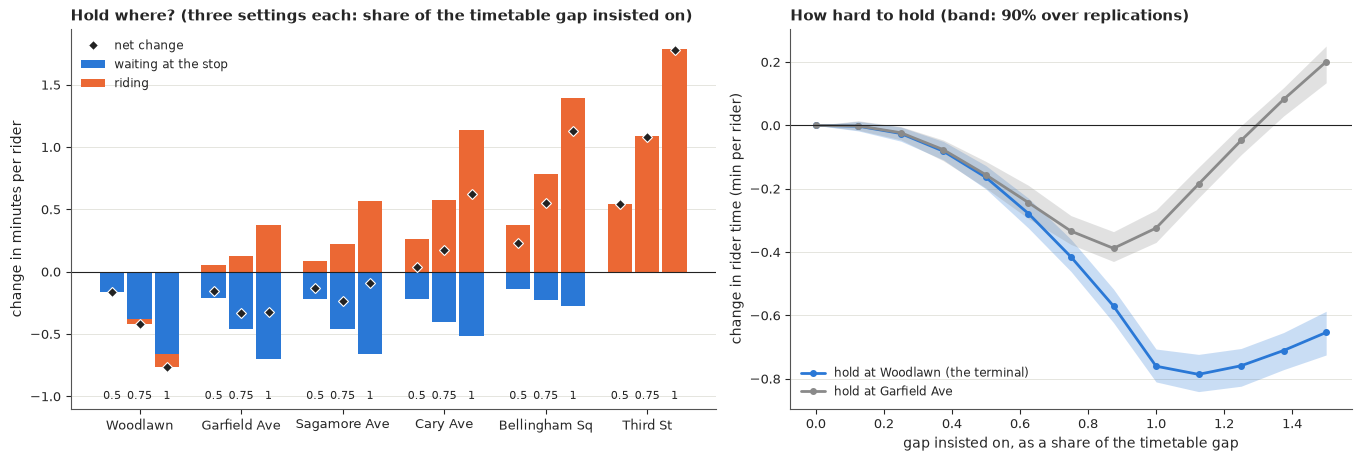

In [17]:
dial = np.arange(0.0, 1.51, 0.125)
t0 = time.time()
terminal = np.array([evaluate(KEPT, TEST, REPS, rule(0, a)) - base for a in dial])
garfield = np.array([evaluate(KEPT, TEST, REPS, rule(1, a)) - base for a in dial])
best = int(np.argmin(terminal[:, :, :2].sum(2).mean(1)))
print(f"terminal dial in {time.time() - t0:.0f} s; rider time is lowest at {dial[best]:.3g} of the timetable gap:")
print(pd.DataFrame({"share of timetable gap": dial, "wait": terminal[:, :, 0].mean(1), "ride": terminal[:, :, 1].mean(1),
                    "total": terminal[:, :, :2].sum(2).mean(1), "held per bus (s)": terminal[:, :, 2].mean(1),
                    "bunched at Third St (points)": terminal[:, :, 3].mean(1) * 100,
                    "rider-hours saved a day": -terminal[:, :, :2].sum(2).mean(1) * RIDERS / 60,
                    "bus-hours held a day": terminal[:, :, 2].mean(1) * BUSES / 3600}).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
x = np.arange(6)
for a, off in zip(ALPHAS, (-0.27, 0.0, 0.27)):
    w = np.array([menu[(k, a)][:, 0].mean() for k in range(6)])
    r = np.array([menu[(k, a)][:, 1].mean() for k in range(6)])
    ax.bar(x + off, w, width=0.24, color=BLUE, label="waiting at the stop" if a == ALPHAS[0] else None)
    ax.bar(x + off, r, width=0.24, color=ORANGE, bottom=np.where(r * w < 0, 0, w), label="riding" if a == ALPHAS[0] else None)
    tot = np.array([menu[(k, a)][:, :2].sum(1) for k in range(6)])
    ax.plot(x + off, tot.mean(1), "D", ms=5.5, color=INK, mec="white", mew=0.8, zorder=4,
            label="net change" if a == ALPHAS[0] else None)
    for xi in x + off:
        ax.text(xi, -1.02, f"{a:g}", ha="center", fontsize=7.6, color=INK)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(x, NAME[:6])
ax.set_ylim(-1.1, 1.95)
ax.set_ylabel("change in minutes per rider")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Hold where? (three settings each: share of the timetable gap insisted on)", loc="left", fontsize=10.5)
tidy(ax)
ax = axes[1]
for arr, colour, label in ((terminal, BLUE, "hold at Woodlawn (the terminal)"), (garfield, MUTED, "hold at Garfield Ave")):
    tot = arr[:, :, :2].sum(2)
    ax.fill_between(dial, *np.quantile(tot, [0.05, 0.95], axis=1), color=colour, alpha=0.25, lw=0)
    ax.plot(dial, tot.mean(1), "o-", color=colour, lw=2, ms=4, label=label)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("gap insisted on, as a share of the timetable gap")
ax.set_ylabel("change in rider time (min per rider)")
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_title("How hard to hold (band: 90% over replications)", loc="left", fontsize=10.5)
tidy(ax);

Without holding, a rider on this route waits 4.5 minutes and rides 17.5, and there are about 4,000
of them on 132 buses between 6:00 and 19:00.

**Where.** The left panel shows the six places, each with three settings. Blue is what the rule does
to waiting, orange what it does to riding, and the diamond is the sum. Waiting falls wherever we
hold, by up to 0.7 minutes per rider, as long as there are stops still to come. The orange bars are
the price. At Woodlawn the trip has not begun, and holding the bus costs nobody a ride. One
timepoint on, at Garfield Ave, the rule with $\alpha = 1$ saves 0.70 minutes of waiting and costs
0.38 of riding. By Cary Ave the riders on board lose more than the riders downstream gain, and at
Third St, after which nobody boards, holding is a pure loss of 1.8 minutes each. A control point in
the middle of the route is the wrong place where nearly everyone rides to the end. It is also where
holding removes the most bunches: at Third St the rule takes 15 to 19 points off the share of gaps
under a minute, and the terminal rule at most 7. Counting bunches would choose the worst rule.

**How hard.** The right panel turns the dial at the terminal. The gain grows steadily up to
$\alpha = 1$, where rider time is down by 0.76 minutes per rider: 0.66 of waiting and 0.10 of
riding, because fewer riders sit on the slow bus at the head of a bunch. Beyond the timetable's gap
there is nothing more to gain. The terminal rule costs no rider a minute on board, and its price is
bus time. With $\alpha = 1$ the average bus stands almost three minutes longer at Woodlawn, about
6.4 bus-hours every weekday for 51 rider-hours saved. With $\alpha = 0.75$ it stands 67 seconds,
2.5 bus-hours for 28 rider-hours. And even the full rule leaves 13% of gaps under a minute at Third St,
down from 20%: evenly spaced buses start sliding again as soon as they are on the street.

The two diagrams below show one simulated November afternoon both ways, chosen because the
difference is easy to see; the averages are in the table.

No holding, 25 November: 22 buses, 0 of them held, for 0 bus-minutes in all; pairs under a minute apart at Third St: 9
Held at Woodlawn to the timetable's gap, 25 November: 22 buses, 17 of them held, for 50 bus-minutes in all; pairs under a minute apart at Third St: 2


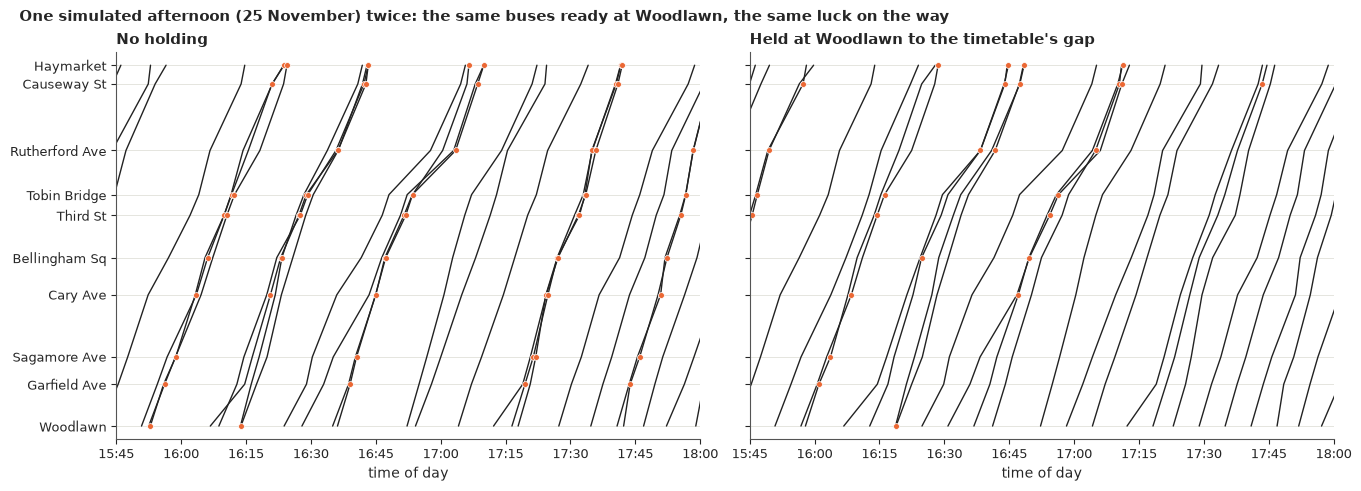

In [18]:
POSTED = rule(0, 1.0)


def close_pairs(sim, t0_, t1_):
    """Pairs of successive buses under a minute apart at Third St, among buses leaving Woodlawn in a window."""
    return int((np.diff(np.sort(sim[(sim[:, 0] >= t0_) & (sim[:, 0] < t1_), 5])) < 60).sum())


found = max(((close_pairs(next(play(KEPT, [d], 3))[0], w, w + 8100)
              - close_pairs(next(play(KEPT, [d], 3, rule=POSTED))[0], w, w + 8100), d, w)
             for d in TEST for w in np.arange(6.5, 16.6, 0.5) * 3600), key=lambda x: x[0])
_, M_DAY, M0 = found
M1 = M0 + 8100
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
fig.suptitle(f"One simulated afternoon ({M_DAY:%d %B}) twice: the same buses ready at Woodlawn, the same luck on the way",
             x=0.01, ha="left", fontsize=11)
for ax, rule_, title in ((axes[0], NO_HOLD, "No holding"), (axes[1], POSTED, "Held at Woodlawn to the timetable's gap")):
    sim, mask, held = next(play(KEPT, [M_DAY], 3, rule=rule_))
    marey(ax, sim, np.ones_like(mask), M0 + 900, M1 + 900)
    ax.set_xlabel("time of day")
    ax.set_title(title, loc="left", fontsize=10.5)
    day = (sim[:, 0] >= M0) & (sim[:, 0] < M1)
    print(f"{title}, {M_DAY:%d %B}: {day.sum()} buses, {(held[day] > 0).sum()} of them held, for {held[day].sum() / 60:.0f} "
          f"bus-minutes in all; pairs under a minute apart at Third St: {close_pairs(sim, M0, M1)}")

> **The choice.** Hold at Woodlawn: no bus leaves until the bus ahead has the timetable's gap on it,
> four minutes in the early peak and six after, and none is held more than five minutes. In the
> simulator this gives each rider back 0.76 minutes, 3.5% of the trip and 15% of the wait, at no
> cost in riding time and a price of about three minutes of standing per bus. A planner short of
> buses takes three quarters of the gap, for less than half the standing and a little over half
> the gain. *Rejected:* holding in mid-route (from Cary Ave on, the riders on board lose more than
> the riders waiting gain), and choosing by the number of bunches (it prefers Third St).
> *Considered:* counting a minute at the stop for more than a minute on the bus; even at two for
> one the table above keeps Woodlawn in front. And rules that look at the bus behind as well as
> the bus ahead, which we leave as an exercise. *What would change our mind:* whether a bus can
> be held at all. A bus that leaves late because it arrived late has no minutes
> to give, and three minutes per bus have to come out of the layover or out of the fleet. That is
> a question for the vehicle records we do not have, and for a trial.

## 6 · Which of our choices mattered?

Four choices in this notebook had a serious rival: noise that is independent from bus to bus; a
dwell term from the bus's own gap, or none at all; departures on schedule; and an account that
counts waiting only, the first measure one thinks of for bunching. That makes
$2 \times 3 \times 2 \times 2 = 24$ planners.

Each planner replays November in his or her own simulator, tries the eighteen rules of part 5 and
no rule at all, and posts the one that looks best in his or her own accounts. We then judge the
posted rule with the full chain and the full accounts. The figure is a specification curve
(Simonsohn, Simmons and Nelson 2020): every defensible analysis, in order of its result, with the
choices that define it underneath.

In [19]:
FORKS = {  # choice: (what we did, what we rejected)
    "noise": ("traffic shared with the bus ahead", "independent from bus to bus"),
    "gap": ("riders shared inside a bunch", "own gap only", "no effect of the gap"),
    "starts": ("recorded departures", "departures on schedule"),
    "account": ("waiting and riding", "waiting only"),
}
OPTIONS = [NO_HOLD] + [rule(k, a) for k in range(6) for a in ALPHAS]
OPTION_NAME = ["no holding"] + [f"{NAME[k]}, {a:g}" for k in range(6) for a in ALPHAS]
OPTION_PLACE = [-1] + [k for k in range(6) for a in ALPHAS]
M_REPS = 8
t0 = time.time()


def believed_world(noise, gap):
    par = [KEPT, on_route(OWN), TRAF][gap]
    return {**par, "rho0": np.zeros_like(par["rho0"])} if noise else par


truth = np.array([evaluate(KEPT, TEST, M_REPS, o) for o in OPTIONS])                   # option x rep x 4
true_total = truth[:, :, :2].sum(2) - truth[0, :, :2].sum(1)
worlds = []
for noise in range(2):
    for gap in range(3):
        par = believed_world(noise, gap)
        for starts in range(2):
            seen_ = np.array([evaluate(par, TEST, M_REPS, o, starts="sched" if starts else "real") for o in OPTIONS])
            for account in range(2):
                score = seen_[:, :, 0] if account else seen_[:, :, :2].sum(2)
                pick = int(np.argmin(score.mean(1)))
                worlds.append({"noise": noise, "gap": gap, "starts": starts, "account": account, "pick": pick,
                               "believed": (score[pick] - score[0]).mean(), "true": true_total[pick].mean(),
                               "lo": np.quantile(true_total[pick], 0.05), "hi": np.quantile(true_total[pick], 0.95),
                               "place": OPTION_PLACE[pick]})
worlds = pd.DataFrame(worlds)
worlds["rule"] = [OPTION_NAME[p] for p in worlds["pick"]]
worlds["rejected"] = (worlds[list(FORKS)] > 0).sum(axis=1)
print(f"{len(worlds)} planners, {len(OPTIONS)} rules each, in {time.time() - t0:.0f} s")
ours = worlds[worlds["rejected"] == 0].iloc[0]
print(f"our choices: {ours['rule']}; believed change {ours['believed']:+.2f}, true {ours['true']:+.2f} min per rider")
print(worlds.groupby("rule").agg(planners=("true", "size"), true_change=("true", "mean")).round(2).to_string())
print(worlds.assign(**{f: [FORKS[f][v] for v in worlds[f]] for f in FORKS})[list(FORKS) + ["rule", "believed", "true"]]
      .round(2).to_string(index=False))
for f in FORKS:
    print(f"{f}:", worlds.groupby(f)["true"].mean().round(3).rename(dict(enumerate(FORKS[f]))).to_dict())

24 planners, 19 rules each, in 9 s
our choices: Woodlawn, 1; believed change -0.77, true -0.77 min per rider
                 planners  true_change
rule                                  
Cary Ave, 1             4         0.61
Garfield Ave, 1         5        -0.32
Sagamore Ave, 1         2        -0.10
Woodlawn, 1            13        -0.77
                            noise                          gap                 starts            account            rule  believed  true
traffic shared with the bus ahead riders shared inside a bunch    recorded departures waiting and riding     Woodlawn, 1     -0.77 -0.77
traffic shared with the bus ahead riders shared inside a bunch    recorded departures       waiting only Garfield Ave, 1     -0.70 -0.32
traffic shared with the bus ahead riders shared inside a bunch departures on schedule waiting and riding     Woodlawn, 1     -0.06 -0.77
traffic shared with the bus ahead riders shared inside a bunch departures on schedule       waiting only Saga

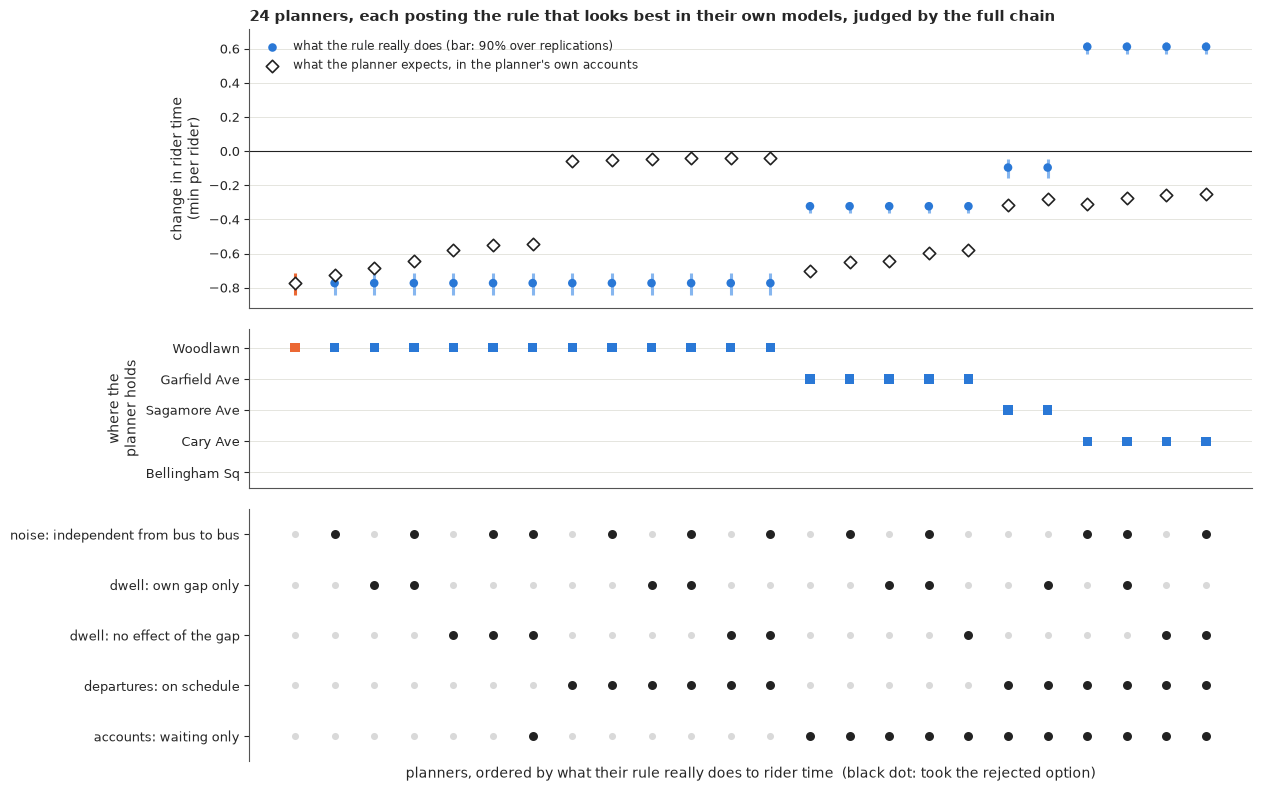

In [20]:
ws = worlds.sort_values(["true", "believed"]).reset_index(drop=True)
fig, axes = plt.subplots(3, 1, figsize=(12.5, 7.8), sharex=True, gridspec_kw={"height_ratios": [2.1, 1.2, 1.9], "hspace": 0.08})
xw = np.arange(len(ws))
is_ours = (ws["rejected"] == 0).to_numpy()
ax = axes[0]
ax.axhline(0, color=INK, lw=0.8)
ax.vlines(xw, ws["lo"], ws["hi"], color=np.where(is_ours, ORANGE, "#86b6ef"), lw=2.2)
ax.scatter(xw, ws["true"], s=38, color=np.where(is_ours, ORANGE, BLUE), zorder=3, lw=0)
ax.scatter([], [], s=38, color=BLUE, lw=0, label="what the rule really does (bar: 90% over replications)")
ax.scatter(xw, ws["believed"], s=40, facecolor="white", edgecolor=INK, lw=1.2, zorder=4, marker="D",
           label="what the planner expects, in the planner's own accounts")
ax.set_ylabel("change in rider time\n(min per rider)")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title(f"{len(ws)} planners, each posting the rule that looks best in their own models, judged by the full chain",
             loc="left")
tidy(ax)
ax = axes[1]
for y_ in range(5):
    ax.axhline(y_, color=GRID, lw=0.6, zorder=0)
ax.scatter(xw, ws["place"], s=46, marker="s", color=np.where(is_ours, ORANGE, BLUE), lw=0)
ax.set_yticks(range(5), NAME[:5])
ax.set_ylim(4.5, -0.6)
ax.set_ylabel("where the\nplanner holds")
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax = axes[2]
dots = [("noise", 1, "noise: independent from bus to bus"), ("gap", 1, "dwell: own gap only"),
        ("gap", 2, "dwell: no effect of the gap"), ("starts", 1, "departures: on schedule"),
        ("account", 1, "accounts: waiting only")]
for r_, (f, level, _) in enumerate(dots):
    on = ws[f].to_numpy() == level
    ax.scatter(xw[~on], np.full((~on).sum(), r_), s=26, color=LIGHT, lw=0)
    ax.scatter(xw[on], np.full(on.sum(), r_), s=42, color=INK, lw=0)
ax.set_yticks(range(len(dots)), [d[2] for d in dots])
ax.set_ylim(len(dots) - 0.5, -0.5)
ax.set_xticks([])
ax.set_xlabel("planners, ordered by what their rule really does to rider time  (black dot: took the rejected option)")
ax.grid(False)
ax.spines[["top", "right", "bottom"]].set_visible(False);

Read the figure from the bottom. Each column is a planner, the black dots say which rejected options
that planner took, the squares say where the planner holds, and the top panel compares what the
planner expects (diamond) with what the full chain says the rule does (dot). Every planner sets the
dial to the full timetable gap. The orange column is this notebook.

**One choice decides the rule: whose minutes are counted.** All twelve planners who count riding as
well as waiting post the same rule, hold at Woodlawn, whatever they believe about noise, dwell or
departures, and all get the same 0.77 minutes (0.76 in part 5, which had more replications). Of the
twelve who count waiting only, one holds at Woodlawn. Five hold at Garfield Ave and get 0.32. Two
hold at Sagamore Ave and get 0.10. Four hold at Cary Ave, expect to save a quarter of a minute of
waiting per rider, and cost each rider 0.6 minutes.

**One choice decides what the planner expects: the departures.** A planner who starts every bus on
schedule and counts both kinds of time still picks the terminal, and expects 0.05 minutes from it,
one fifteenth of what it delivers. In practice that planner posts nothing. This was the choice we
did not know we were making until the first simulator failed its test.

**The models of parts 2 and 3 never change the rule of a planner who counts both kinds of time.**
They move it only among the planners who count waiting alone, from one wrong place to another.
What they change is the expected gain: with recorded departures and full accounts, a planner who
believes the gap has no effect on run times expects 0.55 to 0.58 minutes, one with own-gap dwell
0.64 to 0.68, and one with sharing 0.72 to 0.77. So about three quarters of the gain from holding
at the terminal is arithmetic: even gaps mean shorter waits, with no theory of bunching needed.
The passenger loop adds the last quarter. That is also the answer to the caution of part 3. If some
of what we called dwell is really slow drivers, the gain is somewhere between 0.55 and 0.77, and the
rule is the same.

Most of these pages went on the dynamics, and the dynamics are what make three buses arrive
together. The decision turned on two things that are not dynamics at all: a fact about the terminal
that the records gave up only after a failed test, and a definition of whose time counts.

## Summary

- **Bunching on this route has two sources, and the proposal named one.** Buses leave Woodlawn
  unevenly (7% within a minute of the bus ahead), and the street then triples the bunches by Third
  St (22%). Started on schedule, the full simulator reaches only 10%, and a mean wait of 4.2
  minutes where the route has 5.8.
  *Limit:* we cannot say why departures are uneven; the records do not link a vehicle's trips.
- **Independent segments fit the run times and do bunch, by accident.** They take 7% to 10%. They
  miss that neighbouring buses share traffic (correlations of 0.6 on the streets and 0.9 on the
  bridge at short gaps), and they have no drift: gaps neither grow nor shrink on average. The
  proposal's "never" was wrong and its point was right.
- **Dwell had to be inferred, and the route supplied the test.** An extra minute of gap costs two
  to six seconds of run time on the segments where riders board and nothing where they do not.
  With the season's boarding counts that is 4.2 seconds per boarding rider, once a bunch is allowed
  to share its riders. *Limit:* slow drivers could produce part of the same pattern.
- **The simulator matches the route and not the bus.** On November it gives 19% of gaps under a
  minute at Third St against 22%, a mean wait of 5.7 minutes against 5.8, and the right flow in the
  phase portrait. Its 80% ribbons hold only 60% to 70% of real readings from Cary Ave on, and its
  bunches swap places too easily.
- **The decision: hold at the terminal.** Holding at Woodlawn to the timetable's gap saves 0.76
  minutes per rider at no cost in riding time and about three minutes of standing per bus; the
  same rule at Third St costs every rider 1.8 minutes while removing more bunches. *Limit:* riders
  are assumed to arrive evenly at the season's average rate, and buses are assumed able to wait.
- **What mattered was the account and the start.** Across 24 planners the rule depended on
  whether riding time was counted, and the expected gain on whether departures were taken from the
  records. The travel-time and dwell models moved the expected gain by a quarter and the rule not
  at all.

## Try it yourself

1. **Give each bus a pace.** In `simulate`, add to `z` a term that is drawn once per bus and
   stays with it over the five street segments (try a standard deviation of 0.1 on the log scale,
   and reduce `sigma` to keep the total spread). Do the 80% ribbons now hold 80% of the readings?
   Does the share of bunches at Third St move, and does the holding rule?
2. **The other direction.** Outbound, most riders board at Haymarket and get off in Chelsea. Repeat
   the natural experiment of part 3 on the outbound segments (use alightings where we used
   boardings). Is there a passenger loop when riders mostly leave the bus? Where would you hold?
3. **A rule that looks both ways.** Change `hold_back` so that a bus waits only while the bus
   behind it is further away than the bus ahead (it needs the time at which the next bus will be
   ready, which the replay knows). Does it reach the same rider time with less standing per bus?

In [21]:
print(f"total run time: {time.time() - T_START:.0f} s")

total run time: 132 s
